# CS781 Phase 3. Decoder IA³ for rhetorical role prediction

I adapted the frozen Phase 1 causal decoder with IA³ and added a sentence-level BiGRU and CRF. The saved execution includes the initial run and a separate continuation from its best checkpoint. Epoch numbers in the continuation are relative to that stage.

| Run | Best epoch | Epochs completed | Dev macro F1 | CodaBench macro F1 | Submission ID |
| --- | ---: | ---: | ---: | ---: | ---: |
| Initial run | 15 | 19 | 0.3999 |  |  |
| Continuation | 8 | 14 | 0.4250 | 0.4151 | 990177 |


## 1. Inputs and environment

1. Start a Kaggle session with two T4 GPUs. Use the session's PyTorch installation.
2. Attach `prep_002_mixed16k` with its tokenizer and manifest. Attach the original
   [Phase 1 run](../phase1/phase1_decoder_training.ipynb) `decoder_004_mixed217m` with `best_model.pt`
   and its source files. Set `PREP_INPUT` and `DECODER_INPUT` if automatic
   discovery is ambiguous.
3. Set `RR_DATA_INPUT` to the official data folder if it is already available.
   For the pinned download, enable Internet and provide the Kaggle secret `HF_TOKEN`.
4. Run the initial training stage first. Set `RESUME_INPUT` only for a matching backup
   of the initial run. The continuation uses that run's selected `best_rr.pt`.


In [1]:
%pip install -q huggingface_hub pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import gc
import hashlib
import importlib.metadata
import json
import math
from pathlib import Path
import random
import shutil
import sys
import time

import numpy as np
import pandas as pd
import torch
from IPython.display import display

torch.set_num_threads(2)

RUN_ID = 'decoder_rr_ia3_001'
PREP_INPUT = None
DECODER_INPUT = None
RR_DATA_INPUT = None
RESUME_INPUT = None

ROOT = Path('/kaggle/working/cs781_phase3')
SRC = Path('/kaggle/working/cs781_phase3_decoder_src')
RUN_DIR = ROOT / 'runs' / RUN_ID
for folder in (ROOT, SRC, RUN_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RUN_LEARNING_SMOKE = True
LEARNING_SMOKE_STEPS = 40
RUN_TRAINING = True
TRAIN_MAX_UPDATES_THIS_INVOCATION = None  # Optional deliberate pause after N completed updates.

SETTINGS = {
    'seed': 42,
    'window_sentences': 128,
    'overlap_sentences': 32,
    'chunk_tokens': 256,
    'chunk_microbatch': 8,             # Inside one window on each GPU.
    'global_window_batch': 2,           # One window per GPU on T4 x2.
    'accumulation_steps': 2,            # Four windows per optimizer update.
    'gradient_checkpointing': True,
    'projection_dim': 256,
    'context_hidden': 128,              # Per GRU direction.
    'head_dropout': 0.20,
    'class_weight_cap': 5.0,
    'aux_ce_coefficient': 0.25,
    'ia3_lr': 1e-3,
    'head_lr': 3e-4,
    'crf_lr': 1e-3,
    'weight_decay': 0.01,
    'gradient_clip': 1.0,
    'warmup_fraction': 0.05,
    'minimum_lr_fraction': 0.01,
    'epochs': 20,
    'minimum_epochs': 5,
    'patience': 4,
    'early_stop_min_delta': 1e-4,
    'require_two_gpus': True,
    'max_run_hours': 9.0,
    'save_every_minutes': 3.0,
    'log_every_updates': 10,
    'backup_on_save': True,
}

random.seed(SETTINGS['seed'])
np.random.seed(SETTINGS['seed'])
torch.manual_seed(SETTINGS['seed'])
if not torch.cuda.is_available():
    raise RuntimeError('Enable a Kaggle GPU before running this training notebook.')
if SETTINGS['require_two_gpus'] and torch.cuda.device_count() < 2:
    raise RuntimeError('Select Kaggle T4 x2. Set require_two_gpus=False only for an intentional single-GPU run.')
torch.cuda.manual_seed_all(SETTINGS['seed'])
print('GPUs:', [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
print('Run:', RUN_ID)
print('Working disk free GiB:', round(shutil.disk_usage(ROOT).free / 2**30, 2))

GPUs: ['Tesla T4', 'Tesla T4']
Run: decoder_rr_ia3_001
Working disk free GiB: 19.44


## 2. Implementation

These cells write the original Phase 1 tokenizer and backbone, data preparation, role model, training helpers and course evaluator into the Kaggle working directory. The run checks these sources against its saved provenance.


In [3]:
%%writefile /kaggle/working/cs781_phase3_decoder_src/phase1_utils.py
"""Small file and JSON helpers used by the Phase-1 notebooks."""
import hashlib
import json
import os
import pickle
import zipfile
from pathlib import Path


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def text_hash(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    os.replace(temporary, path)


def atomic_pickle(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with open(temporary, "wb") as file:
        pickle.dump(value, file, protocol=pickle.HIGHEST_PROTOCOL)
        file.flush()
        os.fsync(file.fileno())
    os.replace(temporary, path)


def checked_json(path, value):
    path = Path(path)
    if path.exists() and read_json(path) != value:
        raise ValueError(f"Saved settings differ: {path}. Use a new experiment ID.")
    atomic_json(path, value)


def write_source(path, content):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    raw = content.encode("utf-8") if isinstance(content, str) else content
    if path.exists():
        if path.read_bytes() != raw:
            raise ValueError(f"Saved source differs: {path}. Keep its code or use a new experiment ID.")
        return
    path.write_bytes(raw)


def make_bundle(folder, output_path, archive_root):
    folder, output_path, archive_root = Path(folder), Path(output_path), Path(archive_root)
    temporary = output_path.with_suffix(".zip.tmp")
    with zipfile.ZipFile(temporary, "w", compression=zipfile.ZIP_STORED) as archive:
        for path in sorted(folder.rglob("*")):
            if path.is_file() and "__pycache__" not in path.parts and not path.name.endswith(".tmp"):
                archive.write(path, path.relative_to(archive_root))
    os.replace(temporary, output_path)
    return output_path


Overwriting /kaggle/working/cs781_phase3_decoder_src/phase1_utils.py


In [4]:
%%writefile /kaggle/working/cs781_phase3_decoder_src/a1_tokenizer.py
"""The assignment byte-BPE algorithm, with checkpoints between merges.

Pair counting, lexicographic tie breaking, non-overlapping replacements and
merge-order encoding are unchanged from the completed Phase-1/A3 tokenizer.
"""
import pickle
import re
import time
from collections import Counter
from pathlib import Path
from phase1_utils import atomic_pickle, sha256_file, text_hash


class A1BPETokenizer:
    def __init__(self):
        specials = ["<pad>", "<unk>", "<s>", "</s>"]
        self.vocab = [s.encode("utf-8") for s in specials]
        self.vocab += [bytes([b]) for b in range(256)]
        self.boundary_id = len(self.vocab)
        self.vocab.append(b"")
        self.names = [s.encode("utf-8") for s in specials]
        self.names += [bytes([b]) for b in range(256)]
        self.names.append(b"</w>")
        self.merges = {}
        self.vocab_size = len(self.vocab)

    def fit(self, text, vocab_size, checkpoint_path=None, checkpoint_merges=100,
            stop_after_merges=None):
        if vocab_size < 261:
            raise ValueError("Vocabulary must accommodate bytes and reserved tokens")
        signature = {"text_sha256": text_hash(text), "vocab_size": vocab_size,
                     "algorithm_source_sha256": sha256_file(__file__)}
        checkpoint_path = Path(checkpoint_path) if checkpoint_path is not None else None
        elapsed_before = 0.0
        if checkpoint_path is not None and checkpoint_path.exists():
            with open(checkpoint_path, "rb") as file:
                saved = pickle.load(file)
            if saved["signature"] != signature:
                raise ValueError("BPE checkpoint settings or source differ")
            self.__dict__.update(saved["tokenizer_state"])
            words = saved["words"]
            elapsed_before = saved["elapsed_seconds"]
            print("Resuming BPE vocabulary:", self.vocab_size, flush=True)
        else:
            if self.merges:
                raise ValueError("Use a fresh tokenizer or its saved fitting checkpoint")
            words = Counter(tuple(b + 4 for b in piece.encode("utf-8")) + (self.boundary_id,)
                            for piece in re.findall(r"\S+|\s+", text))
        started = time.monotonic()
        last_saved = started
        merges_this_call = 0
        commit_in_progress = False

        def snapshot():
            if checkpoint_path is not None:
                atomic_pickle(checkpoint_path, {"signature": signature,
                    "tokenizer_state": self.__dict__, "words": words,
                    "elapsed_seconds": elapsed_before + time.monotonic() - started})

        try:
            while len(self.vocab) < vocab_size:
                pair_counts = Counter()
                for symbols, frequency in words.items():
                    for pair in zip(symbols, symbols[1:]):
                        pair_counts[pair] += frequency
                if not pair_counts:
                    break
                pair = min(pair_counts, key=lambda p: (-pair_counts[p], self.names[p[0]], self.names[p[1]]))
                if pair_counts[pair] < 2:
                    break
                new_id = len(self.vocab)
                updated = Counter()
                for symbols, frequency in words.items():
                    result = []
                    j = 0
                    while j < len(symbols):
                        if j + 1 < len(symbols) and symbols[j:j + 2] == pair:
                            result.append(new_id)
                            j += 2
                        else:
                            result.append(symbols[j])
                            j += 1
                    updated[tuple(result)] += frequency
                # Commit the whole merge only after every word has been replaced.
                commit_in_progress = True
                self.vocab.append(self.vocab[pair[0]] + self.vocab[pair[1]])
                self.names.append(self.names[pair[0]] + self.names[pair[1]])
                self.merges[pair] = new_id
                self.vocab_size = len(self.vocab)
                words = updated
                commit_in_progress = False
                merges_this_call += 1
                if len(self.merges) % checkpoint_merges == 0 or time.monotonic() - last_saved >= 60:
                    snapshot()
                    print(f"BPE vocabulary {self.vocab_size:,}/{vocab_size:,} | "
                          f"elapsed {(elapsed_before + time.monotonic() - started)/60:.1f} min", flush=True)
                    last_saved = time.monotonic()
                if stop_after_merges is not None and merges_this_call >= stop_after_merges:
                    break
        finally:
            if not commit_in_progress:
                snapshot()
        return self

    def encode(self, text):
        result = []
        for piece in re.findall(r"\S+|\s+", text):
            symbols = [b + 4 for b in piece.encode("utf-8")] + [self.boundary_id]
            while len(symbols) > 1:
                candidates = [(self.merges[(a, b)], (a, b))
                              for a, b in zip(symbols, symbols[1:]) if (a, b) in self.merges]
                if not candidates:
                    break
                new_id, pair = min(candidates)
                merged = []
                j = 0
                while j < len(symbols):
                    if j + 1 < len(symbols) and (symbols[j], symbols[j + 1]) == pair:
                        merged.append(new_id)
                        j += 2
                    else:
                        merged.append(symbols[j])
                        j += 1
                symbols = merged
            result.extend(symbols)
        return result

    def decode(self, ids):
        return b"".join(self.vocab[i] for i in ids).decode("utf-8")


Overwriting /kaggle/working/cs781_phase3_decoder_src/a1_tokenizer.py


In [5]:
%%writefile /kaggle/working/cs781_phase3_decoder_src/phase1_decoder.py
"""Phase 1 decoder, adapted from completed Assignment 3 Q1."""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class LMConfig:
    vocab_size: int = 16000
    d_model: int = 1024
    n_layers: int = 16
    n_heads: int = 16
    d_ff: int = 4096
    max_seq_len: int = 2560
    dropout: float = 0.1
    norm_first: bool = True
    attention_impl: str = "sdpa"
    attention_scale: float = None
    embedding_scale: float = 32.0


class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, max_seq_len, dropout=0.0,
                 attention_scale=None, attention_impl="sdpa"):
        super().__init__()
        assert d_model % n_heads == 0
        if attention_impl not in ("manual", "sdpa"):
            raise ValueError("attention_impl must be manual or sdpa")
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.attention_scale = 1.0 / math.sqrt(self.d_head) if attention_scale is None else float(attention_scale)
        self.attention_impl = attention_impl
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        if attention_impl == "manual":
            self.register_buffer("causal_mask", torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool)),
                                 persistent=False)

    def forward(self, x):
        B, T, C = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        if self.attention_impl == "manual":
            scores = (q @ k.transpose(-2, -1)) * self.attention_scale
            scores = scores.masked_fill(~self.causal_mask[:T, :T], float("-inf"))
            weights = self.attn_dropout(torch.softmax(scores, dim=-1))
            out = weights @ v
        else:
            out = F.scaled_dot_product_attention(
                q, k, v, is_causal=True, scale=self.attention_scale,
                dropout_p=self.attn_dropout.p if self.training else 0.0,
            )
        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.out_proj(out))


def sinusoidal_positional_encoding(max_len, d_model):
    position = torch.arange(max_len).unsqueeze(1).float()
    frequency = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
    pe = torch.zeros(max_len, d_model)
    pe[:, 0::2] = torch.sin(position * frequency)
    pe[:, 1::2] = torch.cos(position * frequency)
    return pe


class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(),
                                 nn.Linear(d_ff, d_model), nn.Dropout(dropout))

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.norm_first = cfg.norm_first
        self.ln1 = nn.LayerNorm(cfg.d_model)
        self.attn = CausalSelfAttention(cfg.d_model, cfg.n_heads, cfg.max_seq_len, cfg.dropout,
                                      cfg.attention_scale, cfg.attention_impl)
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)

    def forward(self, x):
        if self.norm_first:
            x = x + self.attn(self.ln1(x))
            x = x + self.ffn(self.ln2(x))
        else:
            x = self.ln1(x + self.attn(x))
            x = self.ln2(x + self.ffn(x))
        return x


class DecoderLM(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.register_buffer("pos_emb", sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model),
                             persistent=False)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

        # parameters() counts the tied matrix once.
        for parameter in self.parameters():
            if parameter.ndim > 1:
                nn.init.xavier_uniform_(parameter)
        for module in self.modules():
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, idx, last_positions=None):
        B, T = idx.shape
        if T > self.cfg.max_seq_len:
            raise ValueError("Input exceeds the configured context length")
        x = self.tok_emb(idx) * self.cfg.embedding_scale + self.pos_emb[:T].unsqueeze(0)
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)
        if last_positions is not None:
            x = x[torch.arange(B, device=idx.device), last_positions]
        return self.head(x)


class ModelWithLoss(nn.Module):
    """Compute loss on each GPU before DataParallel gathers the small outputs."""
    def __init__(self, lm, use_amp=True):
        super().__init__()
        self.lm = lm
        self.use_amp = use_amp

    def forward(self, x, y):
        # Enter autocast in each worker thread; do not move the model to half().
        with torch.autocast("cuda", dtype=torch.float16, enabled=self.use_amp and x.is_cuda):
            logits = self.lm(x)
            loss = F.cross_entropy(logits.reshape(-1, self.lm.cfg.vocab_size), y.reshape(-1))
        return loss.unsqueeze(0)


Overwriting /kaggle/working/cs781_phase3_decoder_src/phase1_decoder.py


In [6]:
%%writefile /kaggle/working/cs781_phase3_decoder_src/rr_data.py
import hashlib
import json
import math
import pickle
import re
import shutil
import time
import zipfile
from pathlib import Path
from collections import Counter
import numpy as np
import torch
ROOT = Path('/kaggle/working/cs781_phase3')
INPUT_ROOTS = [Path('/kaggle/input')]

def file_hash(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for part in iter(lambda: f.read(2**20), b''):
            h.update(part)
    return h.hexdigest()

def write_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + '.tmp')
    temp.write_text(json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
    temp.replace(path)

def read_json(path):
    def unique_pairs(pairs):
        result = {}
        for key, value in pairs:
            if key in result:
                raise ValueError(f'Duplicate JSON key: {key!r}')
            result[key] = value
        return result
    def reject_constant(value):
        raise ValueError(f'Invalid JSON constant: {value}')
    return json.loads(Path(path).read_text(encoding='utf-8'),
                      object_pairs_hook=unique_pairs, parse_constant=reject_constant)

def find_input(filename, supplied=None, hint=None, required=True):
    archives = []
    if supplied is not None:
        p = Path(supplied)
        if p.is_file() and p.suffix.lower() == '.zip':
            candidates, archives = [], [p]
        else:
            candidates = [p] if p.is_file() and p.name == filename else list(p.rglob(filename))
            archives = list(p.rglob('*.zip')) if p.is_dir() else []
    else:
        candidates = [p for root in INPUT_ROOTS if root.exists() for p in root.rglob(filename)]
        if hint is not None:
            candidates = [p for p in candidates if hint in str(p)]
    candidates = sorted(set(p.resolve() for p in candidates))
    if len(candidates) == 1:
        return candidates[0]
    if not candidates:
        if supplied is None:
            archives = [p for root in INPUT_ROOTS if root.exists() for p in root.rglob('*.zip')]
        archive_matches = []
        for archive in sorted(set(archives)):
            try:
                with zipfile.ZipFile(archive) as z:
                    for info in z.infolist():
                        if Path(info.filename).name == filename and not info.is_dir():
                            if hint is None or hint in str(archive) + '/' + info.filename:
                                archive_matches.append((archive, info.filename))
            except zipfile.BadZipFile:
                continue
        if len(archive_matches) > 1:
            raise ValueError('Several archive candidates; set an exact input path: ' + str(archive_matches))
        if archive_matches:
            archive, member = archive_matches[0]
            dest = ROOT / 'extracted_inputs' / hashlib.sha256(str(archive.resolve()).encode()).hexdigest()[:12]
            dest.mkdir(parents=True, exist_ok=True)
            metadata_path = dest / 'extraction_record.json'
            records = read_json(metadata_path) if metadata_path.exists() else {}
            with zipfile.ZipFile(archive) as z:
                wanted = [member]
                sibling = str(Path(member).parent / 'cache_manifest.json') if filename == 'tokenizer_state.pkl' else str(Path(member).parent / 'sources/phase1_decoder.py')
                if sibling in z.namelist():
                    wanted.append(sibling)
                for name in wanted:
                    info = z.getinfo(name)
                    target = (dest / name).resolve()
                    if not target.is_relative_to(dest.resolve()):
                        raise ValueError('Unsafe path inside attached ZIP.')
                    record = {'archive_bytes': archive.stat().st_size, 'archive_mtime_ns': archive.stat().st_mtime_ns,
                              'member_crc': info.CRC, 'member_bytes': info.file_size}
                    if target.exists() and target.stat().st_size == info.file_size and records.get(name) == record:
                        continue
                    if shutil.disk_usage(ROOT).free < info.file_size + 256 * 2**20:
                        raise RuntimeError('Insufficient working disk to extract this selected Phase 1 file.')
                    target.parent.mkdir(parents=True, exist_ok=True)
                    temporary = target.with_suffix(target.suffix + '.tmp')
                    with z.open(name) as src, open(temporary, 'wb') as dst:
                        shutil.copyfileobj(src, dst, length=2**20)
                    temporary.replace(target)
                    records[name] = record
                    print('Extracted selected input:', archive.name, '->', name)
            write_json(metadata_path, records)
            return dest / member
    if not candidates and not required:
        return None
    if not candidates:
        raise FileNotFoundError(f'Cannot find {filename}. Attach its extracted input folder or set an exact path.')
    raise ValueError(f'Several candidates for {filename}; set an exact path:\n' + '\n'.join(map(str, candidates)))

def official_labels(obj):
    if isinstance(obj, list):
        result = obj
    elif isinstance(obj, dict) and obj:
        if all(isinstance(v, int) and not isinstance(v, bool) for v in obj.values()):
            if set(obj.values()) != set(range(13)):
                raise ValueError('Expected label IDs 0..12 in label_vocab.json')
            result = [label for label, idx in sorted(obj.items(), key=lambda pair: pair[1])]
        elif all(isinstance(v, str) for v in obj.values()) and all(str(k).isdigit() for k in obj):
            if {int(k) for k in obj} != set(range(13)):
                raise ValueError('Expected label IDs 0..12 in label_vocab.json')
            result = [obj[str(i)] if str(i) in obj else obj[i] for i in range(13)]
        else:
            raise ValueError('Unsupported label_vocab.json mapping; inspect its preview below.')
    else:
        raise ValueError('Unsupported label vocabulary structure.')
    if len(result) != 13 or len(set(result)) != 13 or any(not isinstance(v, str) or not v.strip() for v in result):
        raise ValueError('Expected 13 unique nonempty label strings.')
    return result

def normalize_id(raw_id):
    if not isinstance(raw_id, str) or not raw_id.strip():
        raise ValueError('Document IDs must be nonempty strings.')
    return raw_id[:-4] if raw_id.endswith('.txt') else raw_id

def parse_documents(raw, domain, split, filename):
    if isinstance(raw, list):
        items = [(None, record) for record in raw]
    elif isinstance(raw, dict) and 'text' in raw and 'id' in raw:
        items = [(None, raw)]
    elif isinstance(raw, dict):
        items = list(raw.items())
    else:
        raise ValueError(f'{filename}: unsupported top-level structure.')
    result, seen = [], set()
    for key, record in items:
        if split == 'test' and key is not None and isinstance(record, list):
            record = {'id': key, 'text': record}
        if not isinstance(record, dict):
            raise ValueError(f'{filename}: expected records with id/text/labels; inspect the JSON preview.')
        raw_id = record.get('id', key)
        doc_id = normalize_id(raw_id)
        if key is not None and normalize_id(key) != doc_id:
            raise ValueError(f'{filename}: mapping key and record id disagree.')
        if doc_id in seen:
            raise ValueError(f'{filename}: duplicate normalized document ID {doc_id!r}')
        seen.add(doc_id)
        text = record.get('text')
        if not isinstance(text, list) or any(not isinstance(s, str) for s in text):
            raise ValueError(f'{filename}/{doc_id}: text must be an ordered list of strings.')
        labels = record.get('labels') if split != 'test' else None
        if split != 'test':
            if not isinstance(labels, list) or len(labels) != len(text):
                raise ValueError(f'{filename}/{doc_id}: sentence/label count mismatch.')
            if any(not isinstance(label, str) or label not in LABEL_TO_ID for label in labels):
                raise ValueError(f'{filename}/{doc_id}: unknown or non-string role label.')
        result.append({'domain': domain, 'split': split, 'file': filename, 'raw_id': raw_id,
                       'id': doc_id, 'text': text, 'labels': labels,
                       'test_labels_field_present': split == 'test' and 'labels' in record})
    return result

def sentence_windows(n, width, overlap):
    if not 0 <= overlap < width:
        raise ValueError('Require 0 <= overlap < width.')
    if n == 0:
        return []
    starts = [0]
    while starts[-1] + width < n:
        starts.append(starts[-1] + width - overlap)
    ends = [min(s + width, n) for s in starts]
    boundaries = [0] + [(ends[i-1] + starts[i]) // 2 for i in range(1, len(starts))] + [n]
    windows = [{'start': s, 'end': e, 'owned_start': boundaries[i], 'owned_end': boundaries[i+1]}
               for i, (s, e) in enumerate(zip(starts, ends))]
    ownership = np.zeros(n, dtype=np.int32)
    for w in windows:
        assert w['start'] <= w['owned_start'] <= w['owned_end'] <= w['end']
        ownership[w['owned_start']:w['owned_end']] += 1
    assert (ownership == 1).all()
    return windows

def split_chunks(ids, cap):
    if cap < 3:
        raise ValueError('Chunk cap must leave space for content plus two specials.')
    parts = [ids[i:i + cap - 2] for i in range(0, len(ids), cap - 2)] or [[]]
    return [[BOS_ID] + part + [EOS_ID] for part in parts]

PAD_ID, BOS_ID, EOS_ID = 0, 2, 3


def prepare_rr_data(destination, expected_hashes, revision, supplied=None):
    """Use verified local RR bytes when available; otherwise download seven files."""
    destination = Path(destination)
    relatives = {name: ('Test/' if name.endswith('_test.json') else 'Train/') + name
                 for name in expected_hashes}
    candidates = []
    if supplied is not None:
        p = Path(supplied)
        if not p.is_dir():
            raise ValueError('RR_DATA_INPUT must be an extracted data folder.')
        candidates = [p] + [f.parent.parent for f in p.rglob('CL_train.json')]
    else:
        candidates = [destination, Path('/kaggle/working/cs781_phase3_audit/official_data/Phase_3_RR')]
        candidates += [p.parent.parent for root in INPUT_ROOTS if root.exists()
                       for p in root.rglob('CL_train.json')]
    for candidate in candidates:
        if all((candidate / rel).exists() for rel in relatives.values()):
            if all(file_hash(candidate / relatives[name]) == digest for name, digest in expected_hashes.items()):
                return candidate
            if supplied is not None:
                raise ValueError('Selected RR data differs from the audited official revision.')
    from huggingface_hub import hf_hub_download
    from huggingface_hub.utils import disable_progress_bars
    from kaggle_secrets import UserSecretsClient
    disable_progress_bars()
    try:
        token = UserSecretsClient().get_secret('HF_TOKEN')
    except Exception:
        raise RuntimeError('Enable Internet and the Kaggle secret HF_TOKEN, or attach verified RR files.') from None
    try:
        for name, rel in relatives.items():
            path = hf_hub_download(repo_id='Exploration-Lab/CS-781-Capstone', repo_type='dataset',
                filename='Phase_3_RR/' + rel, revision=revision, token=token,
                local_dir=str(destination.parent))
            if file_hash(path) != expected_hashes[name]:
                raise ValueError('Downloaded RR file differs from the audited hash: ' + name)
            print('RR data ready:', name, flush=True)
    except Exception:
        raise RuntimeError('RR download failed. Check Internet and HF_TOKEN access to the official dataset.') from None
    finally:
        token = None
    return destination


def load_rr_documents(folder):
    global LABEL_TO_ID
    folder = Path(folder)
    labels = official_labels(read_json(folder / 'Train/label_vocab.json'))
    LABEL_TO_ID = {name: i for i, name in enumerate(labels)}
    documents = []
    for domain in ('CL', 'IT'):
        for split in ('train', 'dev', 'test'):
            name = domain + '_' + split + '.json'
            raw = read_json(folder / ('Test' if split == 'test' else 'Train') / name)
            documents.extend(parse_documents(raw, domain, split, name))
    for split in ('train', 'dev', 'test'):
        ids = [d['id'] for d in documents if d['split'] == split]
        if len(ids) != len(set(ids)):
            raise ValueError('Duplicate normalized IDs across domains in ' + split)
    for a, b in (('train', 'dev'), ('train', 'test'), ('dev', 'test')):
        if {d['id'] for d in documents if d['split'] == a} & {d['id'] for d in documents if d['split'] == b}:
            raise ValueError('Document IDs overlap across splits.')
    return labels, documents


def load_tokenizer(path):
    from a1_tokenizer import A1BPETokenizer
    path = Path(path)
    manifest = read_json(path.parent / 'cache_manifest.json')
    if file_hash(path) != manifest['tokenizer_state_sha256']:
        raise ValueError('Tokenizer bytes differ from the preparation manifest.')
    with open(path, 'rb') as f:
        saved = pickle.load(f)
    if saved['signature'] != manifest['tokenizer_signature']:
        raise ValueError('Tokenizer signatures differ.')
    tokenizer = A1BPETokenizer()
    tokenizer.__dict__.update(saved['state'])
    assert tokenizer.vocab[:4] == [b'<pad>', b'<unk>', b'<s>', b'</s>']
    return tokenizer, saved['signature'], manifest


def tokenize_documents(documents, tokenizer, fingerprint, cache_dir):
    cache = Path(cache_dir) / (fingerprint + '.pkl')
    if cache.exists():
        with open(cache, 'rb') as f:
            saved = pickle.load(f)
        if saved['fingerprint'] != fingerprint or len(saved['tokens']) != len(documents):
            raise ValueError('RR token cache identity differs.')
        for doc, tokens, identity in zip(documents, saved['tokens'], saved['identities']):
            if identity != [doc['file'], doc['raw_id']] or len(tokens) != len(doc['text']):
                raise ValueError('RR token cache sentence alignment differs.')
            doc['token_ids'] = tokens
        print('Loaded verified RR token cache.', flush=True)
        return
    from functools import lru_cache
    @lru_cache(maxsize=100000)
    def piece_ids(piece):
        return tuple(tokenizer.encode(piece))
    started = last = time.monotonic()
    for i, doc in enumerate(documents):
        doc['token_ids'] = [[idx for p in re.findall(r'\S+|\s+', sentence) for idx in piece_ids(p)]
                            for sentence in doc['text']]
        if i == 0 or time.monotonic() - last > 30:
            print('Tokenized RR documents:', i + 1, '/', len(documents), flush=True)
            last = time.monotonic()
    cache.parent.mkdir(parents=True, exist_ok=True)
    with open(cache.with_suffix('.tmp'), 'wb') as f:
        pickle.dump({'fingerprint': fingerprint, 'tokens': [d['token_ids'] for d in documents],
                     'identities': [[d['file'], d['raw_id']] for d in documents]}, f, protocol=pickle.HIGHEST_PROTOCOL)
    cache.with_suffix('.tmp').replace(cache)
    print('Tokenization minutes:', round((time.monotonic() - started) / 60, 2), flush=True)


def make_windows(documents, width, overlap, split):
    result = []
    for di, doc in enumerate(documents):
        if doc['split'] != split:
            continue
        for w in sentence_windows(len(doc['text']), width, overlap):
            result.append(dict(w, doc_index=di, n_document_sentences=len(doc['text'])))
    return result


def class_weights(documents, labels, cap=5.0):
    counts = Counter(label for d in documents if d['split'] == 'train' for label in d['labels'])
    maximum = max(counts.values())
    weights = [min(math.sqrt(maximum / counts[k]), cap) if counts[k] else 0.0 for k in labels]
    return torch.tensor(weights, dtype=torch.float32), [counts[k] for k in labels]


def collate_windows(documents, windows, label_to_id, cap):
    rows = []
    for w in windows:
        doc = documents[w['doc_index']]
        chunks, owners, weights = [], [], []
        for owner, ids in enumerate(doc['token_ids'][w['start']:w['end']]):
            for chunk in split_chunks(ids, cap):
                chunks.append(chunk)
                owners.append(owner)
                weights.append(max(len(chunk) - 2, 1))
        rows.append((chunks, owners, weights, doc, w))
    if not rows:
        raise ValueError('Cannot collate an empty batch.')
    batch_size = len(rows)
    max_chunks = max(len(r[0]) for r in rows)
    max_tokens = max(len(c) for r in rows for c in r[0])
    max_sentences = max(r[4]['end'] - r[4]['start'] for r in rows)
    batch = {
        'ids': torch.full((batch_size, max_chunks, max_tokens), PAD_ID, dtype=torch.long),
        'lengths': torch.zeros(batch_size, max_chunks, dtype=torch.long),
        'owners': torch.zeros(batch_size, max_chunks, dtype=torch.long),
        'chunk_weights': torch.zeros(batch_size, max_chunks, dtype=torch.float32),
        'sentence_mask': torch.zeros(batch_size, max_sentences, dtype=torch.bool),
        'owned_mask': torch.zeros(batch_size, max_sentences, dtype=torch.bool),
        'targets': torch.full((batch_size, max_sentences), -100, dtype=torch.long),
        'use_start': torch.zeros(batch_size, dtype=torch.bool),
        'use_end': torch.zeros(batch_size, dtype=torch.bool),
    }
    for b, (chunks, owners, weights, doc, w) in enumerate(rows):
        n = w['end'] - w['start']
        batch['sentence_mask'][b, :n] = True
        lo, hi = w['owned_start'] - w['start'], w['owned_end'] - w['start']
        batch['owned_mask'][b, lo:hi] = True
        batch['use_start'][b] = w['owned_start'] == 0
        batch['use_end'][b] = w['owned_end'] == len(doc['text'])
        if doc['labels'] is not None:
            batch['targets'][b, :n] = torch.tensor([label_to_id[k] for k in doc['labels'][w['start']:w['end']]])
        for j, chunk in enumerate(chunks):
            batch['ids'][b, j, :len(chunk)] = torch.tensor(chunk)
            batch['lengths'][b, j] = len(chunk)
            batch['owners'][b, j] = owners[j]
            batch['chunk_weights'][b, j] = weights[j]
    return batch


def supervision_denominators(batch, weights):
    targets = batch['targets'][batch['owned_mask']]
    if (targets < 0).any():
        raise ValueError('An owned training position lacks a label.')
    return int(len(targets)), float(weights.cpu()[targets].sum())


def load_own_checkpoint(path):
    try:
        return torch.load(path, map_location='cpu', weights_only=False, mmap=True)
    except RuntimeError as error:
        if 'mmap' not in str(error):
            raise
        return torch.load(path, map_location='cpu', weights_only=False)


Overwriting /kaggle/working/cs781_phase3_decoder_src/rr_data.py


In [7]:
%%writefile /kaggle/working/cs781_phase3_decoder_src/rr_model.py
"""Original causal decoder + IA3 + sentence BiGRU + unconstrained learned CRF."""
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint


class OutputScale(nn.Module):
    def __init__(self, linear):
        super().__init__()
        self.base = linear
        self.scale = nn.Parameter(torch.ones(linear.out_features))

    def forward(self, x):
        y = self.base(x)
        return y * self.scale.to(y.dtype)


class InputScale(nn.Module):
    def __init__(self, linear):
        super().__init__()
        self.base = linear
        self.scale = nn.Parameter(torch.ones(linear.in_features))

    def forward(self, x):
        return self.base(x * self.scale.to(x.dtype))


class SentenceBiGRU(nn.Module):
    """One manually gated GRU per direction; reset-after convention."""
    def __init__(self, input_size, hidden):
        super().__init__()
        self.hidden = hidden
        self.x_layers = nn.ModuleList([nn.Linear(input_size, 3 * hidden) for _ in range(2)])
        self.h_layers = nn.ModuleList([nn.Linear(hidden, 3 * hidden) for _ in range(2)])

    def forward(self, x):
        outputs = []
        for direction in range(2):
            hidden = x.new_zeros(self.hidden)
            states = [None] * len(x)
            order = range(len(x)) if direction == 0 else range(len(x) - 1, -1, -1)
            for i in order:
                xr, xz, xn = self.x_layers[direction](x[i]).chunk(3)
                hr, hz, hn = self.h_layers[direction](hidden).chunk(3)
                reset, update = torch.sigmoid(xr + hr), torch.sigmoid(xz + hz)
                candidate = torch.tanh(xn + reset * hn)
                hidden = (1 - update) * candidate + update * hidden
                states[i] = hidden
            outputs.append(torch.stack(states))
        return torch.cat(outputs, dim=-1)


class LinearChainCRF(nn.Module):
    def __init__(self, n_labels):
        super().__init__()
        self.transitions = nn.Parameter(torch.zeros(n_labels, n_labels))
        self.start = nn.Parameter(torch.zeros(n_labels))
        self.end = nn.Parameter(torch.zeros(n_labels))

    def log_partition(self, emissions, use_start=True, use_end=True):
        if len(emissions) == 0:
            return emissions.sum() * 0
        alpha = emissions[0] + (self.start if use_start else 0)
        for emission in emissions[1:]:
            alpha = emission + torch.logsumexp(alpha[:, None] + self.transitions, dim=0)
        return torch.logsumexp(alpha + (self.end if use_end else 0), dim=0)

    def gold_score(self, emissions, labels, use_start=True, use_end=True):
        if len(labels) == 0:
            return emissions.sum() * 0
        score = emissions.gather(1, labels[:, None]).sum()
        if len(labels) > 1:
            score = score + self.transitions[labels[:-1], labels[1:]].sum()
        if use_start:
            score = score + self.start[labels[0]]
        if use_end:
            score = score + self.end[labels[-1]]
        return score

    def nll(self, emissions, labels, use_start=True, use_end=True):
        return self.log_partition(emissions, use_start, use_end) - self.gold_score(emissions, labels, use_start, use_end)

    @torch.no_grad()
    def decode(self, emissions, use_start=True, use_end=True):
        if len(emissions) == 0:
            return []
        delta = emissions[0] + (self.start if use_start else 0)
        back = []
        for emission in emissions[1:]:
            scores, choices = (delta[:, None] + self.transitions).max(dim=0)
            delta = scores + emission
            back.append(choices)
        last = int((delta + (self.end if use_end else 0)).argmax())
        path = [last]
        for choices in reversed(back):
            last = int(choices[last])
            path.append(last)
        return list(reversed(path))


class DecoderRR(nn.Module):
    def __init__(self, lm, n_labels, class_weights, settings):
        super().__init__()
        self.lm = lm
        self.settings = dict(settings)
        self.n_labels = n_labels
        for p in lm.parameters():
            p.requires_grad_(False)
        for block in lm.blocks:
            block.attn.k_proj = OutputScale(block.attn.k_proj)
            block.attn.v_proj = OutputScale(block.attn.v_proj)
            block.ffn.net[2] = InputScale(block.ffn.net[2])
        projection = settings['projection_dim']
        self.projection = nn.Linear(lm.cfg.d_model, projection)
        self.context = SentenceBiGRU(projection, settings['context_hidden'])
        self.dropout = nn.Dropout(settings['head_dropout'])
        self.classifier = nn.Linear(2 * settings['context_hidden'], n_labels)
        self.crf = LinearChainCRF(n_labels)
        self.register_buffer('class_weights', class_weights.clone().float(), persistent=False)

    def encode_chunks(self, ids, last_content):
        x = self.lm.tok_emb(ids) * self.lm.cfg.embedding_scale + self.lm.pos_emb[:ids.shape[1]].unsqueeze(0)
        for block in self.lm.blocks:
            if self.training and self.settings['gradient_checkpointing']:
                x = checkpoint(block, x, use_reentrant=False)
            else:
                x = block(x)
        x = self.lm.ln_f(x)
        return x[torch.arange(len(ids), device=ids.device), last_content]

    def one_window(self, ids, lengths, owners, weights, n_sentences):
        lengths_list = lengths.detach().cpu().tolist()
        n_chunks = sum(n > 0 for n in lengths_list)
        if n_chunks == 0:
            raise ValueError('An RR window must contain sentences and chunks.')
        vectors = []
        microbatch = self.settings['chunk_microbatch']
        for start in range(0, n_chunks, microbatch):
            end = min(start + microbatch, n_chunks)
            length = max(lengths_list[start:end])
            last = lengths[start:end] - 2
            vectors.append(self.encode_chunks(ids[start:end, :length], last))
        vectors = torch.cat(vectors).float()
        owner = owners[:n_chunks]
        weight = weights[:n_chunks].float()
        pooled = vectors.new_zeros((n_sentences, vectors.shape[-1])).index_add(0, owner, vectors * weight[:, None])
        denominator = vectors.new_zeros(n_sentences).index_add(0, owner, weight)
        pooled = pooled / denominator[:, None]
        features = self.dropout(torch.tanh(self.projection(pooled)))
        return self.classifier(self.dropout(self.context(features)))

    def forward(self, ids, lengths, owners, chunk_weights, sentence_mask, owned_mask,
                targets, use_start, use_end, mode='loss'):
        emissions, losses = [], []
        max_sentences = sentence_mask.shape[1]
        # Autocast is entered here because DataParallel uses worker threads.
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=ids.is_cuda):
            for b in range(len(ids)):
                n = int(sentence_mask[b].sum())
                logits = self.one_window(ids[b], lengths[b], owners[b], chunk_weights[b], n)
                if mode == 'emissions':
                    emissions.append(F.pad(logits.float(), (0, 0, 0, max_sentences - n)))
                else:
                    keep = owned_mask[b, :n]
                    gold = targets[b, :n][keep]
                    scores = logits[:n][keep].float()
                    if len(gold) == 0 or (gold < 0).any():
                        raise ValueError('The owned region requires contiguous valid gold labels.')
                    with torch.autocast(device_type='cuda', enabled=False):
                        crf = self.crf.nll(scores, gold, bool(use_start[b]), bool(use_end[b]))
                        ce = F.cross_entropy(scores, gold, weight=self.class_weights.float(), reduction='sum')
                    device_index = ids.device.index if ids.is_cuda else -1
                    losses.append(torch.stack([crf, ce, crf.new_tensor(float(device_index))]))
        return torch.stack(emissions) if mode == 'emissions' else torch.stack(losses)


def bare(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def trainable_state(model):
    return {name: p.detach().cpu().clone() for name, p in bare(model).named_parameters() if p.requires_grad}


def load_trainable_state(model, state):
    expected = {name: p for name, p in bare(model).named_parameters() if p.requires_grad}
    if set(expected) != set(state):
        raise ValueError('Checkpoint trainable parameter names differ.')
    with torch.no_grad():
        for name, p in expected.items():
            if tuple(p.shape) != tuple(state[name].shape):
                raise ValueError('Checkpoint parameter shape differs: ' + name)
            p.copy_(state[name].to(device=p.device, dtype=p.dtype))


Overwriting /kaggle/working/cs781_phase3_decoder_src/rr_model.py


In [8]:
%%writefile /kaggle/working/cs781_phase3_decoder_src/rr_engine.py
"""RR evaluation, global loss normalization, checkpoints, and resumable training."""
import copy
import gc
import hashlib
import json
import math
from pathlib import Path
import random
import shutil
import subprocess
import sys
import time
import zipfile

import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score, precision_recall_fscore_support

from rr_data import collate_windows, supervision_denominators, write_json
from rr_model import bare, trainable_state, load_trainable_state, LinearChainCRF


def rng_state():
    return {'python': random.getstate(), 'numpy': np.random.get_state(), 'torch': torch.get_rng_state(),
            'cuda': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}


def restore_rng(state):
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'].cpu())
    for i, saved in enumerate(state['cuda'][:torch.cuda.device_count()]):
        torch.cuda.set_rng_state(saved.cpu(), i)


def optimizer_for(model, settings, rate_multiplier=1.0):
    groups = {}
    for name, parameter in bare(model).named_parameters():
        if not parameter.requires_grad:
            continue
        if name.endswith('.scale'):
            kind, rate, decay = 'ia3', settings['ia3_lr'], 0.0
        elif name.startswith('crf.'):
            kind, rate, decay = 'crf', settings['crf_lr'], 0.0
        else:
            kind, rate = 'head', settings['head_lr']
            decay = settings['weight_decay'] if parameter.ndim > 1 else 0.0
        key = (kind, decay)
        if key not in groups:
            groups[key] = {'params': [], 'lr': rate * rate_multiplier, 'weight_decay': decay, 'kind': kind}
        groups[key]['params'].append(parameter)
    return torch.optim.AdamW(list(groups.values()), betas=(0.9, 0.999), eps=1e-8, foreach=False)


def scheduler_for(optimizer, total_updates, settings):
    warmup = max(1, math.ceil(total_updates * settings['warmup_fraction']))
    minimum = settings['minimum_lr_fraction']
    def factor(step):
        if step < warmup:
            return (step + 1) / warmup
        progress = min(1.0, (step - warmup) / max(total_updates - warmup - 1, 1))
        return minimum + (1 - minimum) * 0.5 * (1 + math.cos(math.pi * progress))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, factor)


def feed(model, batch, mode='loss'):
    if isinstance(model, nn.DataParallel):
        return model(**batch, mode=mode)
    device = next(model.parameters()).device
    return model(**{key: value.to(device) for key, value in batch.items()}, mode=mode)


def combined_loss(stats, sentence_count, weight_sum, ce_coefficient):
    if sentence_count <= 0 or weight_sum <= 0:
        raise ValueError('A training update requires positive supervision denominators.')
    return stats[:, 0].sum() / sentence_count + ce_coefficient * stats[:, 1].sum() / weight_sum


def cpu_crf(model):
    base = bare(model)
    crf = LinearChainCRF(base.n_labels)
    crf.load_state_dict({k: v.detach().float().cpu() for k, v in base.crf.state_dict().items()})
    return crf.eval()


@torch.no_grad()
def predict_emissions(model, documents, windows, labels, split, settings):
    model.eval()
    label_to_id = {name: i for i, name in enumerate(labels)}
    records = {i: np.zeros((len(doc['text']), len(labels)), dtype=np.float32)
               for i, doc in enumerate(documents) if doc['split'] == split}
    covered = {i: np.zeros(len(documents[i]['text']), dtype=bool) for i in records}
    started = time.monotonic()
    for start in range(0, len(windows), settings['global_window_batch']):
        part = windows[start:start + settings['global_window_batch']]
        batch = collate_windows(documents, part, label_to_id, settings['chunk_tokens'])
        emissions = feed(model, batch, mode='emissions').float().cpu().numpy()
        for b, w in enumerate(part):
            di = w['doc_index']
            lo, hi = w['owned_start'], w['owned_end']
            if covered[di][lo:hi].any():
                raise ValueError('A sentence was assigned emissions more than once.')
            records[di][lo:hi] = emissions[b, lo - w['start']:hi - w['start']]
            covered[di][lo:hi] = True
    if any(not mask.all() for mask in covered.values()):
        raise ValueError('Some supplied sentences received no emissions.')
    return records, time.monotonic() - started


def metrics_for(gold, pred, labels):
    if len(gold) != len(pred) or not gold:
        raise ValueError('Metrics need aligned nonempty lists.')
    precision, recall, f1, support = precision_recall_fscore_support(gold, pred, labels=labels, zero_division=0)
    present = [label for label in labels if label in set(gold)]
    return {
        'macro_f1': float(f1_score(gold, pred, labels=labels, average='macro', zero_division=0)),
        'macro_precision': float(precision_score(gold, pred, labels=labels, average='macro', zero_division=0)),
        'macro_recall': float(recall_score(gold, pred, labels=labels, average='macro', zero_division=0)),
        'present_label_macro_f1': float(f1_score(gold, pred, labels=present, average='macro', zero_division=0)),
        'accuracy': float(np.mean(np.asarray(gold) == np.asarray(pred))),
        'fixed_label_f1_ceiling': len(present) / len(labels),
        'sentences': len(gold),
        'per_label': {name: {'precision': float(precision[i]), 'recall': float(recall[i]),
                              'f1': float(f1[i]), 'support': int(support[i]), 'predicted': pred.count(name)}
                      for i, name in enumerate(labels)},
        'confusion_matrix': confusion_matrix(gold, pred, labels=labels).tolist(),
    }


@torch.no_grad()
def evaluate(model, documents, windows, labels, split, settings, output_dir=None, prefix='evaluation'):
    records, seconds = predict_emissions(model, documents, windows, labels, split, settings)
    crf = cpu_crf(model)
    label_to_id = {name: i for i, name in enumerate(labels)}
    predictions, independent = {}, {}
    golds, preds, by_domain = [], [], {'CL': ([], []), 'IT': ([], [])}
    nll, ce, weighted_ce, n, weight_sum = 0.0, 0.0, 0.0, 0, 0.0
    weights = bare(model).class_weights.detach().float().cpu()
    errors = []
    for di, emissions in records.items():
        doc = documents[di]
        tensor = torch.from_numpy(emissions)
        path = crf.decode(tensor)
        predicted = [labels[k] for k in path]
        predictions[doc['raw_id']] = predicted
        independent[doc['raw_id']] = [labels[k] for k in emissions.argmax(1)] if len(emissions) else []
        if len(predicted) != len(doc['text']):
            raise ValueError('Sentence-count mismatch after full-document decoding.')
        if doc['labels'] is None:
            continue
        gold = doc['labels']
        golds.extend(gold)
        preds.extend(predicted)
        by_domain[doc['domain']][0].extend(gold)
        by_domain[doc['domain']][1].extend(predicted)
        if len(gold):
            targets = torch.tensor([label_to_id[k] for k in gold])
            nll += float(crf.nll(tensor, targets))
            ce += float(F.cross_entropy(tensor, targets, reduction='sum'))
            weighted_ce += float(F.cross_entropy(tensor, targets, weight=weights, reduction='sum'))
            weight_sum += float(weights[targets].sum())
            n += len(gold)
        for i, (actual, guess) in enumerate(zip(gold, predicted)):
            if actual != guess and len(errors) < 100:
                errors.append({'domain': doc['domain'], 'raw_id': doc['raw_id'], 'sentence_index': i,
                    'gold': actual, 'prediction': guess, 'text': doc['text'][i][:600],
                    'previous_sentence': doc['text'][i - 1][:300] if i else None,
                    'next_sentence': doc['text'][i + 1][:300] if i + 1 < len(gold) else None})
    report = {'split': split, 'prediction_seconds': seconds, 'documents': len(records)}
    if golds:
        report['combined'] = metrics_for(golds, preds, labels)
        report['domains'] = {domain: metrics_for(g, p, labels) for domain, (g, p) in by_domain.items() if g}
        independent_flat = [guess for di in records for guess in independent[documents[di]['raw_id']]]
        report['independent_emission_macro_f1'] = metrics_for(golds, independent_flat, labels)['macro_f1']
        report['losses'] = {'document_crf_nll_per_sentence': nll / max(n, 1),
                            'unweighted_sentence_ce': ce / max(n, 1),
                            'weighted_sentence_ce': weighted_ce / max(weight_sum, 1e-12)}
    if output_dir is not None:
        output_dir = Path(output_dir)
        write_json(output_dir / (prefix + '_metrics.json'), report)
        write_json(output_dir / (prefix + '_predictions.json'), predictions)
        write_json(output_dir / (prefix + '_error_samples.json'), errors)
    return predictions, report, records


def official_check(predictions, documents, labels, evaluator_path, output_dir, prefix):
    output_dir = Path(output_dir)
    for domain in ('CL', 'IT'):
        write_json(output_dir / (prefix + '_' + domain + '_truth.json'),
                   {d['raw_id']: d['labels'] for d in documents if d['split'] == 'dev' and d['domain'] == domain})
    pred_path = output_dir / (prefix + '_prediction.json')
    write_json(pred_path, predictions)
    write_json(output_dir / 'labels.json', labels)
    result = subprocess.run([sys.executable, str(evaluator_path),
        '--truth-cl', str(output_dir / (prefix + '_CL_truth.json')),
        '--truth-it', str(output_dir / (prefix + '_IT_truth.json')),
        '--prediction', str(pred_path), '--labels', str(output_dir / 'labels.json')], capture_output=True, text=True)
    if result.returncode:
        raise RuntimeError('Official evaluator failed: ' + result.stdout + result.stderr)
    (output_dir / (prefix + '_official_evaluator.txt')).write_text(result.stdout, encoding='utf-8')
    return result.stdout


def atomic_checkpoint(path, payload):
    path = Path(path)
    if shutil.disk_usage(path.parent).free < 256 * 2**20:
        raise RuntimeError('Not enough working disk for a resumable checkpoint.')
    temporary = path.with_suffix(path.suffix + '.tmp')
    torch.save(payload, temporary)
    temporary.replace(path)


def write_backup(run_dir, destination=None):
    run_dir = Path(run_dir)
    destination = Path(destination) if destination is not None else run_dir.parent / (run_dir.name + '_backup.zip')
    temporary = destination.with_suffix('.tmp')
    with zipfile.ZipFile(temporary, 'w', compression=zipfile.ZIP_DEFLATED) as z:
        for path in sorted(run_dir.rglob('*')):
            if path.is_file() and not path.name.endswith('.tmp'):
                z.write(path, arcname=run_dir.name + '/' + str(path.relative_to(run_dir)))
    temporary.replace(destination)
    return destination


def restore_backup(supplied, run_dir):
    if supplied is None:
        return
    supplied, run_dir = Path(supplied), Path(run_dir)
    if (run_dir / 'last.pt').exists():
        return
    if supplied.suffix.lower() == '.zip':
        with zipfile.ZipFile(supplied) as z:
            lasts = [p for p in z.namelist() if Path(p).name == 'last.pt']
            if len(lasts) != 1:
                raise ValueError('Resume ZIP must contain exactly one RR last.pt.')
            parent = Path(lasts[0]).parent
            for member in z.infolist():
                relative = Path(member.filename)
                if member.is_dir() or not relative.is_relative_to(parent):
                    continue
                target = (run_dir / relative.relative_to(parent)).resolve()
                if not target.is_relative_to(run_dir.resolve()):
                    raise ValueError('Unsafe path in resume ZIP.')
                target.parent.mkdir(parents=True, exist_ok=True)
                with z.open(member) as src, open(target, 'wb') as dst:
                    shutil.copyfileobj(src, dst, length=2**20)
    else:
        source = supplied.parent if supplied.is_file() else supplied
        if not (source / 'last.pt').exists():
            matches = list(source.rglob('last.pt'))
            if len(matches) != 1:
                raise ValueError('Select the exact RR resume folder or last.pt.')
            source = matches[0].parent
        for path in source.rglob('*'):
            if path.is_file():
                target = run_dir / path.relative_to(source)
                target.parent.mkdir(parents=True, exist_ok=True)
                if path.resolve() != target.resolve():
                    shutil.copy2(path, target)
    print('Restored RR resume files:', run_dir, flush=True)


def train(model, documents, train_windows, dev_windows, labels, weights, settings,
          protocol, run_dir, evaluator_path, stop_after_updates=None):
    run_dir = Path(run_dir)
    label_to_id = {label: i for i, label in enumerate(labels)}
    n_batches = math.ceil(len(train_windows) / settings['global_window_batch'])
    updates_per_epoch = math.ceil(n_batches / settings['accumulation_steps'])
    optimizer = optimizer_for(model, settings)
    scheduler = scheduler_for(optimizer, updates_per_epoch * settings['epochs'], settings)
    device = next(model.parameters()).device
    scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda', init_scale=1024)
    state = {'epoch': 0, 'next_batch': 0, 'optimizer_updates': 0, 'skipped_updates': 0,
             'best_f1': -1.0, 'best_epoch': None, 'bad_epochs': 0, 'early_stop_reference': -1.0,
             'completed': False, 'history': [], 'epoch_crf_sum': 0.0, 'epoch_ce_sum': 0.0,
             'epoch_sentences': 0, 'epoch_weight_sum': 0.0, 'epoch_train_seconds': 0.0}
    last_path = run_dir / 'last.pt'
    if last_path.exists():
        saved = torch.load(last_path, map_location='cpu', weights_only=False)
        if saved['protocol'] != protocol:
            raise ValueError('Resume protocol differs. Restore the original settings or choose a new RUN_ID.')
        load_trainable_state(model, saved['trainable_state'])
        optimizer.load_state_dict(saved['optimizer_state'])
        scheduler.load_state_dict(saved['scheduler_state'])
        scaler.load_state_dict(saved['scaler_state'])
        state = saved['training_state']
        restore_rng(saved['rng_state'])
        del saved
        print('Resumed epoch', state['epoch'] + 1, 'next batch', state['next_batch'], flush=True)
    if state['completed']:
        print('Run already complete; use its selected best checkpoint.', flush=True)
        return state
    started = last_saved = time.monotonic()
    invocation_updates = 0

    def save_last():
        atomic_checkpoint(last_path, {'protocol': protocol, 'trainable_state': trainable_state(model),
            'optimizer_state': optimizer.state_dict(), 'scheduler_state': scheduler.state_dict(),
            'scaler_state': scaler.state_dict(), 'training_state': copy.deepcopy(state), 'rng_state': rng_state()})
        write_json(run_dir / 'history.json', state['history'])
        if settings.get('backup_on_save', True):
            write_backup(run_dir)

    def save_best(epoch, metrics, predictions):
        atomic_checkpoint(run_dir / 'best_rr.pt', {'protocol': protocol, 'trainable_state': trainable_state(model),
                                                  'epoch': epoch, 'metrics': metrics})
        write_json(run_dir / 'best_dev_metrics.json', metrics)
        write_json(run_dir / 'best_dev_predictions.json', predictions)

    try:
        if state['best_epoch'] is None:
            predictions, initial, _ = evaluate(model, documents, dev_windows, labels, 'dev', settings,
                                                run_dir, 'initial_dev')
            official_check(predictions, documents, labels, evaluator_path, run_dir, 'initial_dev')
            state['best_f1'] = state['early_stop_reference'] = initial['combined']['macro_f1']
            state['best_epoch'] = 0
            state['history'].append({'kind': 'initial_dev', 'epoch': 0, 'dev': initial})
            save_best(0, initial, predictions)
            save_last()
        while state['epoch'] < settings['epochs']:
            epoch = state['epoch']
            order = np.random.default_rng(settings['seed'] + epoch).permutation(len(train_windows))
            ordered = [train_windows[int(i)] for i in order]
            batches = [ordered[i:i + settings['global_window_batch']]
                       for i in range(0, len(ordered), settings['global_window_batch'])]
            model.train()
            for group_start in range(state['next_batch'], len(batches), settings['accumulation_steps']):
                group_started = time.monotonic()
                group = batches[group_start:group_start + settings['accumulation_steps']]
                prepared = [collate_windows(documents, part, label_to_id, settings['chunk_tokens']) for part in group]
                denominators = [supervision_denominators(batch, weights) for batch in prepared]
                n_sentences = sum(n for n, _ in denominators)
                weight_sum = sum(w for _, w in denominators)
                optimizer.zero_grad(set_to_none=True)
                crf_sum, ce_sum = 0.0, 0.0
                for batch in prepared:
                    stats = feed(model, batch)
                    loss = combined_loss(stats, n_sentences, weight_sum, settings['aux_ce_coefficient'])
                    if not torch.isfinite(loss):
                        raise RuntimeError('Nonfinite RR loss. Last complete update remains resumable.')
                    scaler.scale(loss).backward()
                    crf_sum += float(stats[:, 0].detach().sum())
                    ce_sum += float(stats[:, 1].detach().sum())
                scaler.unscale_(optimizer)
                norm = nn.utils.clip_grad_norm_([p for p in bare(model).parameters() if p.requires_grad], settings['gradient_clip'])
                previous_scale = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                skipped = scaler.get_scale() < previous_scale
                if not skipped:
                    scheduler.step()
                    state['optimizer_updates'] += 1
                    invocation_updates += 1
                state['skipped_updates'] += int(skipped)
                state['next_batch'] = group_start + len(group)
                state['epoch_crf_sum'] += crf_sum
                state['epoch_ce_sum'] += ce_sum
                state['epoch_sentences'] += n_sentences
                state['epoch_weight_sum'] += weight_sum
                state['epoch_train_seconds'] += time.monotonic() - group_started
                row = {'kind': 'train_update', 'epoch': epoch + 1, 'next_batch': state['next_batch'],
                    'optimizer_updates': state['optimizer_updates'], 'amp_skipped': bool(skipped),
                    'window_crf_nll_per_sentence': crf_sum / n_sentences,
                    'weighted_sentence_ce': ce_sum / weight_sum,
                    'gradient_norm': float(norm) if torch.isfinite(norm) else None,
                    'learning_rates': {g['kind']: float(g['lr']) for g in optimizer.param_groups}}
                state['history'].append(row)
                if group_start == 0 or state['optimizer_updates'] % settings['log_every_updates'] == 0:
                    print(f"Epoch {epoch+1}: batches {state['next_batch']}/{len(batches)} | "
                          f"CRF/sentence {row['window_crf_nll_per_sentence']:.4f} | "
                          f"weighted CE {row['weighted_sentence_ce']:.4f} | "
                          f"updates {state['optimizer_updates']} | skipped {state['skipped_updates']}", flush=True)
                paused = (time.monotonic() - started >= settings['max_run_hours'] * 3600 or
                          (stop_after_updates is not None and invocation_updates >= stop_after_updates))
                if paused or time.monotonic() - last_saved >= settings['save_every_minutes'] * 60:
                    save_last()
                    last_saved = time.monotonic()
                if paused:
                    print('Paused after a complete update; resume with the same RUN_ID.', flush=True)
                    return state
            predictions, dev, _ = evaluate(model, documents, dev_windows, labels, 'dev', settings,
                                            run_dir, f'epoch_{epoch+1:02d}_dev')
            _, training, _ = evaluate(model, documents, train_windows, labels, 'train', settings,
                                      run_dir, f'epoch_{epoch+1:02d}_train')
            score = dev['combined']['macro_f1']
            if score > state['best_f1']:
                state['best_f1'], state['best_epoch'] = score, epoch + 1
                save_best(epoch + 1, dev, predictions)
            if score > state['early_stop_reference'] + settings['early_stop_min_delta']:
                state['early_stop_reference'], state['bad_epochs'] = score, 0
            else:
                state['bad_epochs'] += 1
            state['history'].append({'kind': 'epoch', 'epoch': epoch + 1, 'train': training, 'dev': dev,
                'train_update_seconds': state['epoch_train_seconds'],
                'window_crf_nll_per_sentence': state['epoch_crf_sum'] / max(state['epoch_sentences'], 1),
                'weighted_sentence_ce': state['epoch_ce_sum'] / max(state['epoch_weight_sum'], 1e-12)})
            print(f"Epoch {epoch+1}: train F1 {training['combined']['macro_f1']:.4f} | "
                  f"dev F1 {score:.4f} / ceiling {dev['combined']['fixed_label_f1_ceiling']:.4f} | "
                  f"CL {dev['domains']['CL']['macro_f1']:.4f} | IT {dev['domains']['IT']['macro_f1']:.4f} | "
                  f"best epoch {state['best_epoch']}", flush=True)
            state['epoch'] = epoch + 1
            state['next_batch'] = 0
            for key in ('epoch_crf_sum', 'epoch_ce_sum', 'epoch_weight_sum', 'epoch_train_seconds'):
                state[key] = 0.0
            state['epoch_sentences'] = 0
            state['completed'] = (state['epoch'] >= settings['epochs'] or
                (state['epoch'] >= settings['minimum_epochs'] and state['bad_epochs'] >= settings['patience']))
            save_last()
            last_saved = time.monotonic()
            if state['completed']:
                break
    except KeyboardInterrupt:
        optimizer.zero_grad(set_to_none=True)
        if not last_path.exists():
            raise
        # An interrupt could occur part-way through AdamW. Restore an atomic
        # completed checkpoint rather than serializing possibly partial updates.
        saved = torch.load(last_path, map_location='cpu', weights_only=False)
        load_trainable_state(model, saved['trainable_state'])
        state = saved['training_state']
        restore_rng(saved['rng_state'])
        del saved
        print('Interrupted; restored the latest complete saved update. Unsaved progress was discarded.', flush=True)
    finally:
        optimizer.zero_grad(set_to_none=True)
        del optimizer, scheduler, scaler
        gc.collect()
        if device.type == 'cuda':
            torch.cuda.empty_cache()
    return state


def export_selected(model, documents, dev_windows, test_windows, labels, settings, protocol, run_dir, evaluator_path):
    run_dir = Path(run_dir)
    saved = torch.load(run_dir / 'best_rr.pt', map_location='cpu', weights_only=False)
    if saved['protocol'] != protocol:
        raise ValueError('Selected checkpoint protocol differs.')
    load_trainable_state(model, saved['trainable_state'])
    epoch = saved['epoch']
    del saved
    dev_predictions, dev, dev_emissions = evaluate(model, documents, dev_windows, labels, 'dev', settings,
                                                   run_dir, 'selected_dev')
    output = official_check(dev_predictions, documents, labels, evaluator_path, run_dir, 'selected_dev')
    predictions, test, _ = evaluate(model, documents, test_windows, labels, 'test', settings)
    expected = {d['raw_id']: len(d['text']) for d in documents if d['split'] == 'test'}
    if set(predictions) != set(expected):
        raise ValueError('Test output document IDs differ.')
    for did, count in expected.items():
        if len(predictions[did]) != count or any(label not in labels for label in predictions[did]):
            raise ValueError('Invalid test output for ' + did)
    write_json(run_dir / 'prediction.json', predictions)
    submission = run_dir.parent / (run_dir.name + '_submission.zip')
    with zipfile.ZipFile(submission, 'w', compression=zipfile.ZIP_DEFLATED) as z:
        z.write(run_dir / 'prediction.json', arcname='prediction.json')
    np.savez(run_dir / 'selected_dev_emissions.npz',
             **{'doc_' + str(di): array for di, array in dev_emissions.items()})
    write_json(run_dir / 'selected_dev_emission_index.json',
               {str(di): documents[di]['raw_id'] for di in dev_emissions})
    summary = {'best_epoch': epoch, 'selected_dev': dev, 'test_prediction_seconds': test['prediction_seconds'],
               'test_documents': len(expected), 'test_sentences': sum(expected.values()),
               'submission_zip': str(submission), 'checkpoint_format': 'trainable IA3/context/classifier/CRF state; original Phase 1 dependency required'}
    write_json(run_dir / 'run_summary.json', summary)
    print(output)
    print('Selected epoch:', epoch, '| submission:', submission, flush=True)
    return summary


def save_diagnostics(run_dir):
    run_dir = Path(run_dir)
    path = run_dir.parent / (run_dir.name + '_diagnostics.zip')
    with zipfile.ZipFile(path, 'w', compression=zipfile.ZIP_DEFLATED) as z:
        for f in sorted(run_dir.rglob('*')):
            if f.is_file() and f.suffix in ('.json', '.csv', '.png', '.py', '.txt'):
                z.write(f, arcname=run_dir.name + '/' + str(f.relative_to(run_dir)))
    backup = write_backup(run_dir)
    return path, backup


Overwriting /kaggle/working/cs781_phase3_decoder_src/rr_engine.py


In [15]:
%%writefile /kaggle/working/cs781_phase3_decoder_src/rr_checks.py
"""Small numerical and learning checks; all temporary updates are discarded."""
import gc
import itertools
from pathlib import Path
import time

import torch
from torch import nn
import torch.nn.functional as F

from rr_data import collate_windows, supervision_denominators, write_json
from rr_model import bare, trainable_state, load_trainable_state, LinearChainCRF
from rr_engine import feed, combined_loss, optimizer_for, rng_state, restore_rng


def crf_self_test():
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(19)
        crf = LinearChainCRF(3).double()
        with torch.no_grad():
            for p in crf.parameters():
                p.normal_(0, 0.2)
        emissions = torch.randn(4, 3, dtype=torch.float64, requires_grad=True)
        for use_start, use_end in ((True, True), (False, False), (True, False), (False, True)):
            paths = [torch.tensor(p) for p in itertools.product(range(3), repeat=4)]
            scores = torch.stack([crf.gold_score(emissions, p, use_start, use_end) for p in paths])
            torch.testing.assert_close(crf.log_partition(emissions, use_start, use_end), torch.logsumexp(scores, 0))
            expected = paths[int(scores.argmax())].tolist()
            assert crf.decode(emissions, use_start, use_end) == expected
            crf.nll(emissions, paths[0], use_start, use_end).backward(retain_graph=True)
            assert torch.isfinite(emissions.grad).all()
        zero = LinearChainCRF(3)
        one = torch.tensor([[0.2, -0.1, 0.8]])
        torch.testing.assert_close(zero.nll(one, torch.tensor([2])), F.cross_entropy(one, torch.tensor([2])))
        assert zero.decode(one) == [2]
    return {'status': 'passed', 'checks': ['partition vs exhaustive enumeration', 'Viterbi vs exhaustive search',
                                          'all four start/end boundary combinations', 'finite gradients', 'length-one CE identity']}


def learning_windows(documents, width=8):
    candidates = []
    for di, doc in enumerate(documents):
        if doc['split'] != 'train' or len(doc['text']) < width:
            continue
        for start in range(0, len(doc['text']) - width + 1, max(width // 2, 1)):
            labels = doc['labels'][start:start + width]
            changes = sum(a != b for a, b in zip(labels, labels[1:]))
            score = (len(set(labels)), changes)
            candidates.append((score, {'doc_index': di, 'start': start, 'end': start + width,
                'owned_start': start, 'owned_end': start + width, 'n_document_sentences': len(doc['text'])}))
    candidates.sort(key=lambda pair: pair[0], reverse=True)
    selected = []
    for _, w in candidates:
        if not selected or w['doc_index'] != selected[0]['doc_index']:
            selected.append(w)
        if len(selected) == 2:
            break
    if not selected:
        raise ValueError('No training windows available for the learning check.')
    if len(selected) == 1:
        selected.append(dict(selected[0]))
    return selected


@torch.no_grad()
def local_learning_metrics(model, batch, labels):
    model.eval()
    scores = feed(model, batch, mode='emissions').float().cpu()
    kept_scores, kept_targets = [], []
    for b in range(len(scores)):
        keep = batch['owned_mask'][b]
        kept_scores.append(scores[b][keep])
        kept_targets.append(batch['targets'][b][keep])
    scores, targets = torch.cat(kept_scores), torch.cat(kept_targets)
    return {'unweighted_ce': float(F.cross_entropy(scores, targets)),
            'emission_accuracy': float((scores.argmax(1) == targets).float().mean())}


def assert_grads(model):
    base = bare(model)
    if any(p.grad is not None for p in base.parameters() if not p.requires_grad):
        raise AssertionError('An original frozen Phase 1 parameter received a gradient.')
    adapters = [p for name, p in base.named_parameters() if name.endswith('.scale')]
    if any(p.grad is None for p in adapters):
        raise AssertionError('An IA3 scale has no gradient path.')
    if not any(p.grad.abs().sum() > 0 for p in adapters):
        raise AssertionError('Every IA3 gradient is zero.')
    grads = [p.grad for p in base.parameters() if p.requires_grad and p.grad is not None]
    if not grads or any(not torch.isfinite(g).all() for g in grads):
        raise AssertionError('Trainable gradients are missing or nonfinite.')


def run_smoke_checks(model, documents, train_windows, labels, weights, settings, run_dir,
                     learning_steps=40, run_learning=True):
    run_dir = Path(run_dir)
    initial = trainable_state(model)
    initial_rng = rng_state()
    report = {'crf': crf_self_test(), 'two_gpu_required': bool(settings.get('require_two_gpus', False))}
    device = next(model.parameters()).device
    optimizer = None
    try:
        if settings.get('require_two_gpus', False) and (not isinstance(model, nn.DataParallel) or len(model.device_ids) != 2):
            raise AssertionError('Select Kaggle T4 x2; the default run requires two devices.')
        mini = learning_windows(documents)
        label_to_id = {label: i for i, label in enumerate(labels)}
        batch = collate_windows(documents, mini, label_to_id, settings['chunk_tokens'])
        count, denominator = supervision_denominators(batch, weights)

        # Evaluation mode disables dropout while retaining autograd for this comparison.
        model.eval()
        model.zero_grad(set_to_none=True)
        stats = feed(model, batch)
        loss = combined_loss(stats, count, denominator, settings['aux_ce_coefficient'])
        (loss * 128).backward()
        assert_grads(model)
        parallel_grads = {name: p.grad.detach().float().cpu().clone() / 128
                          for name, p in bare(model).named_parameters() if p.requires_grad and p.grad is not None}
        report['device_indices_seen'] = sorted(set(int(i) for i in stats[:, 2].detach().cpu().tolist()))
        if isinstance(model, nn.DataParallel):
            assert report['device_indices_seen'] == sorted(model.device_ids)
            model.zero_grad(set_to_none=True)
            serial = feed(bare(model), batch)
            serial_loss = combined_loss(serial, count, denominator, settings['aux_ce_coefficient'])
            (serial_loss * 128).backward()
            numerator, norm = 0.0, 0.0
            for name, p in bare(model).named_parameters():
                if name in parallel_grads:
                    reference = p.grad.detach().float().cpu() / 128
                    numerator += float((parallel_grads[name] - reference).square().sum())
                    norm += float(reference.square().sum())
            relative = (numerator / max(norm, 1e-20)) ** 0.5
            report['parallel_vs_serial'] = {'loss_difference': abs(float(loss) - float(serial_loss)),
                                             'gradient_relative_l2_error': relative}
            if relative > 0.03 or abs(float(loss) - float(serial_loss)) > 0.01:
                raise AssertionError('Two-GPU loss/gradient normalization differs from the serial reference.')
        model.zero_grad(set_to_none=True)
        del parallel_grads, stats, loss
        gc.collect()
        if device.type == 'cuda':
            torch.cuda.empty_cache()

        # A real heavy full-width batch includes one window on each GPU.
        heavy = sorted(train_windows, key=lambda w: sum(len(ids) for ids in
                       documents[w['doc_index']]['token_ids'][w['start']:w['end']]), reverse=True)[:settings['global_window_batch']]
        heavy_batch = collate_windows(documents, heavy, label_to_id, settings['chunk_tokens'])
        heavy_count, heavy_denominator = supervision_denominators(heavy_batch, weights)
        optimizer = optimizer_for(model, settings)
        scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda', init_scale=1024)
        if device.type == 'cuda':
            for i in range(torch.cuda.device_count()):
                torch.cuda.reset_peak_memory_stats(i)
        model.train()
        started = time.monotonic()
        heavy_stats = feed(model, heavy_batch)
        heavy_loss = combined_loss(heavy_stats, heavy_count, heavy_denominator, settings['aux_ce_coefficient'])
        scaler.scale(heavy_loss).backward()
        scaler.unscale_(optimizer)
        assert_grads(model)
        nn.utils.clip_grad_norm_([p for p in bare(model).parameters() if p.requires_grad], settings['gradient_clip'])
        scaler.step(optimizer)
        scaler.update()
        if device.type == 'cuda':
            torch.cuda.synchronize()
        report['full_batch'] = {'status': 'passed', 'windows': len(heavy), 'owned_sentences': heavy_count,
            'seconds': time.monotonic() - started,
            'peak_allocated_gib': [torch.cuda.max_memory_allocated(i) / 2**30 for i in range(torch.cuda.device_count())],
            'peak_reserved_gib': [torch.cuda.max_memory_reserved(i) / 2**30 for i in range(torch.cuda.device_count())]}
        optimizer.zero_grad(set_to_none=True)
        del optimizer, scaler, heavy_stats, heavy_loss
        optimizer = None
        load_trainable_state(model, initial)

        if run_learning:
            before = local_learning_metrics(model, batch, labels)
            optimizer = optimizer_for(model, settings, rate_multiplier=5.0)
            scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda', init_scale=1024)
            for step in range(learning_steps):
                model.train()
                optimizer.zero_grad(set_to_none=True)
                stats = feed(model, batch)
                loss = combined_loss(stats, count, denominator, settings['aux_ce_coefficient'])
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_([p for p in bare(model).parameters() if p.requires_grad], settings['gradient_clip'])
                scaler.step(optimizer)
                scaler.update()
                if step == 0 or (step + 1) % 10 == 0:
                    print('Temporary learning check:', step + 1, '/', learning_steps, '| loss', float(loss.detach()), flush=True)
            after = local_learning_metrics(model, batch, labels)
            passed = (after['unweighted_ce'] < 0.85 * before['unweighted_ce'] and
                      (after['emission_accuracy'] >= before['emission_accuracy'] + 0.10 or after['emission_accuracy'] >= 0.90))
            report['learning'] = {'before': before, 'after': after, 'steps': learning_steps,
                                  'windows': mini, 'status': 'passed' if passed else 'failed'}
            if not passed:
                raise AssertionError('Tiny learning check did not improve enough. Inspect smoke_checks.json before training.')
        else:
            report['learning'] = {'status': 'skipped_by_configuration'}
        report['status'] = 'passed'
    except Exception as error:
        report['status'] = 'failed'
        report['failure'] = str(error)
        raise
    finally:
        if optimizer is not None:
            optimizer.zero_grad(set_to_none=True)
        model.zero_grad(set_to_none=True)
        load_trainable_state(model, initial)
        restore_rng(initial_rng)
        write_json(run_dir / 'smoke_checks.json', report)
        gc.collect()
        if device.type == 'cuda':
            torch.cuda.empty_cache()
    print('CRF, gradient/device, full-batch and temporary learning checks passed. Initial state restored.', flush=True)
    return report


Overwriting /kaggle/working/cs781_phase3_decoder_src/rr_checks.py


In [10]:
%%writefile /kaggle/working/cs781_phase3_decoder_src/evaluate_phase3.py
#!/usr/bin/env python3
"""Local evaluator for Phase 3.

The competition scorer evaluates two gold/reference JSON files together and
one participant prediction.json. This local evaluator mirrors that setup
using the student's own held-out splits.

Usage:
  python evaluate_phase3.py \
      --truth-cl cl_test_truth.json \
      --truth-it it_test_truth.json \
      --prediction prediction.json \
      --labels labels.json

Each truth file must be a JSON object mapping document IDs to ordered lists of
sentence labels. prediction.json must have the same structure and contain
predictions for documents from both reference files.

labels.json may be either:
  ["Label1", "Label2", ...]
or a label->id / id->label mapping.
"""
import argparse
import json
import sys

from sklearn.metrics import f1_score, precision_score, recall_score

EXPECTED_LABEL_COUNT = 13


def load_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def normalize_id(doc_id):
    if not isinstance(doc_id, str) or not doc_id.strip():
        raise ValueError("Document IDs must be non-empty strings.")
    return doc_id[:-4] if doc_id.endswith(".txt") else doc_id


def load_vocab(data):
    if isinstance(data, list):
        labels = data
    elif isinstance(data, dict) and data:
        values = list(data.values())
        if all(isinstance(v, int) and not isinstance(v, bool) for v in values):
            # label -> integer ID
            labels = list(data.keys())
        elif all(isinstance(v, str) for v in values):
            # integer/string ID -> label
            labels = values
        else:
            raise ValueError("Unsupported labels.json format.")
    else:
        raise ValueError("labels.json must be a non-empty list or object.")

    if len(labels) != EXPECTED_LABEL_COUNT:
        raise ValueError(
            f"Expected {EXPECTED_LABEL_COUNT} labels, found {len(labels)}."
        )
    if any(not isinstance(label, str) or not label.strip() for label in labels):
        raise ValueError("Labels must be unique non-empty strings.")
    if len(set(labels)) != len(labels):
        raise ValueError("Labels must be unique non-empty strings.")
    return labels


def normalize_reference(data, source_name):
    if not isinstance(data, dict):
        raise ValueError(f"{source_name}: reference data must be a JSON object.")

    normalized = {}
    for raw_id, labels in data.items():
        doc_id = normalize_id(raw_id)
        if doc_id in normalized:
            raise ValueError(
                f"{source_name}: duplicate document ID after .txt normalization: {doc_id}"
            )
        normalized[doc_id] = labels
    return normalized


def normalize_predictions(data):
    if not isinstance(data, dict):
        raise ValueError("prediction.json must be a JSON object mapping document IDs to label lists.")

    normalized = {}
    for raw_id, labels in data.items():
        doc_id = normalize_id(raw_id)
        if doc_id in normalized:
            raise ValueError(
                f"prediction.json: duplicate document ID after .txt normalization: {doc_id}"
            )
        normalized[doc_id] = labels
    return normalized


def main():
    parser = argparse.ArgumentParser(
        description=(
            "Evaluate Phase 3 sentence-label predictions on two local held-out "
            "reference splits, mirroring the competition's combined scoring setup."
        )
    )
    parser.add_argument(
        "--truth-cl",
        required=True,
        help="Local held-out reference JSON for the CL split.",
    )
    parser.add_argument(
        "--truth-it",
        required=True,
        help="Local held-out reference JSON for the IT split.",
    )
    parser.add_argument(
        "--prediction",
        required=True,
        help="Participant prediction JSON covering documents from both splits.",
    )
    parser.add_argument(
        "--labels",
        required=True,
        help="Public Phase 3 label vocabulary JSON.",
    )
    args = parser.parse_args()

    truth_cl = normalize_reference(load_json(args.truth_cl), "--truth-cl")
    truth_it = normalize_reference(load_json(args.truth_it), "--truth-it")
    predictions = normalize_predictions(load_json(args.prediction))
    labels = load_vocab(load_json(args.labels))
    allowed = set(labels)

    overlap = set(truth_cl) & set(truth_it)
    if overlap:
        sample = sorted(overlap)[:5]
        suffix = "..." if len(overlap) > 5 else ""
        raise ValueError(
            "The two reference splits contain overlapping document IDs: "
            + ", ".join(sample)
            + suffix
        )

    truth = {}
    truth.update(truth_cl)
    truth.update(truth_it)

    if set(truth) != set(predictions):
        missing = sorted(set(truth) - set(predictions))
        extra = sorted(set(predictions) - set(truth))
        parts = [
            f"missing={len(missing)}",
            f"extra={len(extra)}",
        ]
        if missing:
            parts.append(f"example missing ID(s)={missing[:5]}")
        if extra:
            parts.append(f"example extra ID(s)={extra[:5]}")
        raise ValueError("ID mismatch: " + "; ".join(parts))

    y_true = []
    y_pred = []

    for doc_id in truth:
        gold = truth[doc_id]
        pred = predictions[doc_id]

        if not isinstance(gold, list) or not isinstance(pred, list):
            raise ValueError(f"{doc_id}: labels must be JSON lists.")
        if len(gold) != len(pred):
            raise ValueError(
                f"{doc_id}: sentence-count mismatch ({len(gold)} vs {len(pred)})."
            )
        if any(label not in allowed for label in gold + pred):
            raise ValueError(f"{doc_id}: unknown label encountered.")

        y_true.extend(gold)
        y_pred.extend(pred)

    score = f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)
    macro_precision = precision_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)
    macro_recall = recall_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)

    print(f"CL documents: {len(truth_cl)}")
    print(f"IT documents: {len(truth_it)}")
    print(f"Total documents: {len(truth)}")
    print(f"Total sentences: {len(y_true)}")
    print(f"Macro-F1:        {score:.6f}")
    print(f"Macro-Precision: {macro_precision:.6f}")
    print(f"Macro-Recall:    {macro_recall:.6f}")


if __name__ == "__main__":
    try:
        main()
    except Exception as exc:
        print(f"EVALUATION FAILED: {exc}", file=sys.stderr)
        sys.exit(1)


Overwriting /kaggle/working/cs781_phase3_decoder_src/evaluate_phase3.py


## 3. Official splits and sentence windows

The notebook verifies the seven `Phase_3_RR` files at the pinned revision and reuses the 16K byte BPE tokenizer from Phase 1. I trained on the official CL and IT training sets together and kept the official document-level dev and test splits. The scorer uses a fixed vocabulary of 13 roles. Two roles are absent from combined dev, giving a perfect-prediction dev ceiling of 11/13.

The token model processes chunks of up to 256 tokens, including BOS and EOS. Longer sentences retain all their chunks, which are combined by content length. A bidirectional GRU contextualizes the sentence vectors in 128-sentence windows with 32-sentence overlap. Each sentence contributes supervised loss and inference emissions through one owned window. I reassemble those emissions in order and decode one CRF path per document.


In [11]:
sys.path.insert(0, str(SRC))
import rr_data
from rr_data import (file_hash, read_json, write_json, find_input, prepare_rr_data,
    load_rr_documents, load_tokenizer, tokenize_documents, make_windows, class_weights,
    load_own_checkpoint)
from rr_model import DecoderRR, bare, trainable_state, load_trainable_state
from phase1_decoder import DecoderLM, LMConfig
from rr_engine import (restore_backup, train, export_selected, save_diagnostics,
    evaluate, official_check, atomic_checkpoint)
from rr_checks import run_smoke_checks

rr_data.ROOT = ROOT
rr_data.INPUT_ROOTS = [Path('/kaggle/input')]

In [12]:
HF_REVISION = '89edba6a44d6bb9593fd13b6895b5cd3b06eb82e'
EXPECTED_RR_HASHES = {'CL_train.json': '2fdad020443ad33734a8c3a59f4fbae72582e0535692708ad902473087333ed1', 'CL_dev.json': '95ec2dac8b4c869f9fd1ae434546103b93d9c0a5340b2e5a7e611773519dbbcc', 'IT_train.json': 'a9111869c768c1adfb492ba03df72b14d77fcce9f468a2a167ccf9d29a3b010b', 'IT_dev.json': '825e158bfcb46c1001dc0062d43bdd8f4060c5214ec465aedd2c58d28da1b20a', 'label_vocab.json': 'd4d0175f792a5349ccc028ef3a1d220374169e999550441e84378dcf39e9ae45', 'CL_test.json': '33547ab29f5ae9afda36d92d779aa955676ae1d31df0ca479f09abfeeb48f248', 'IT_test.json': '3117dbe4a909bdec4628c200ed8ed2617a651d633296b41977b00f8b556dbc81'}

DATA = prepare_rr_data(ROOT / 'official_data/Phase_3_RR', EXPECTED_RR_HASHES, HF_REVISION, RR_DATA_INPUT)
labels, documents = load_rr_documents(DATA)
tokenizer_path = find_input('tokenizer_state.pkl', PREP_INPUT,
                            hint='prep_002_mixed16k' if PREP_INPUT is None else None)
tokenizer, tokenizer_signature, preparation_manifest = load_tokenizer(tokenizer_path)
phase1_checkpoint = find_input('best_model.pt', DECODER_INPUT,
                               hint='decoder_004_mixed217m' if DECODER_INPUT is None else None)
tokenizer_sha = file_hash(tokenizer_path)
fingerprint = hashlib.sha256(json.dumps({'data_hashes': EXPECTED_RR_HASHES,
    'tokenizer_sha256': tokenizer_sha}, sort_keys=True).encode()).hexdigest()
tokenize_documents(documents, tokenizer, fingerprint, ROOT / 'token_cache')
weights, counts = class_weights(documents, labels, SETTINGS['class_weight_cap'])
train_windows = make_windows(documents, SETTINGS['window_sentences'], SETTINGS['overlap_sentences'], 'train')
dev_windows = make_windows(documents, SETTINGS['window_sentences'], SETTINGS['overlap_sentences'], 'dev')
test_windows = make_windows(documents, SETTINGS['window_sentences'], SETTINGS['overlap_sentences'], 'test')

display(pd.DataFrame({'label': labels, 'training_sentences': counts, 'weight': weights.tolist()}))
for split in ('train', 'dev', 'test'):
    selected = [d for d in documents if d['split'] == split]
    print(split, '| documents', len(selected), '| sentences', sum(len(d['text']) for d in selected))
print('Windows:', {'train': len(train_windows), 'dev': len(dev_windows), 'test': len(test_windows)})
print('Tokenizer vocabulary:', len(tokenizer.vocab), '| preparation:', tokenizer_path.parent)
print('Phase 1 decoder:', phase1_checkpoint)

Loaded verified RR token cache.


,label,training_sentences,weight
0,Fact,4098,1.024469
1,Issue,107,5.000000
2,ArgumentPetitioner,1613,1.632930
3,ArgumentRespondent,1348,1.786240
4,Statute,1099,1.978271
5,Dissent,284,3.891576
6,PrecedentReliedUpon,1945,1.487048
7,PrecedentNotReliedUpon,569,2.749341
8,PrecedentOverruled,3,5.000000
9,RulingByLowerCourt,874,2.218345


train | documents 80 | sentences 16845
dev | documents 10 | sentences 2142
test | documents 10 | sentences 2197
Windows: {'train': 197, 'dev': 24, 'test': 27}
Tokenizer vocabulary: 16000 | preparation: /kaggle/input/datasets/ash9201kk/prep-2/cs781_phase1/preparation/prep_002_mixed16k
Phase 1 decoder: /kaggle/input/datasets/ash9201kk/decoder-004/cs781_phase1/runs/decoder_004_mixed217m/best_model.pt


## 4. Initialize the IA³ model

IA³ applies learned scales to the attention keys and values and to the feed-forward activations. The scales start at one. I use the last content state of each causal chunk for pooling and train the scales and task head, 660,688 parameters in total.


In [17]:
import shutil
import importlib
import rr_checks

saved_source = RUN_DIR / 'sources' / 'rr_checks.py'
active_source = SRC / 'rr_checks.py'
expected_hash = read_json(RUN_DIR / 'protocol.json')['source_sha256']['rr_checks.py']

assert saved_source.exists(), f"Missing saved source: {saved_source}"
assert file_hash(saved_source) == expected_hash, "Saved source does not match the trained run."

shutil.copy2(saved_source, active_source)
assert file_hash(active_source) == expected_hash

importlib.invalidate_caches()
rr_checks = importlib.reload(rr_checks)
run_smoke_checks = rr_checks.run_smoke_checks

print("Restored the exact smoke-check source used for training.")
print("SHA256:", file_hash(active_source))

Restored the exact smoke-check source used for training.
SHA256: a01acb2e6336ca65a484cc05631cbbb522caeb7fceba3b71cdd548be4bdac30c


In [18]:
restore_backup(RESUME_INPUT, RUN_DIR)
saved = load_own_checkpoint(phase1_checkpoint)
if saved['tokenizer_signature'] != tokenizer_signature:
    raise ValueError('Phase 1 decoder and preparation use different tokenizers.')
cfg = LMConfig(**saved['model_config'])
if cfg.vocab_size != len(tokenizer.vocab) or SETTINGS['chunk_tokens'] > cfg.max_seq_len:
    raise ValueError('Vocabulary or context limit differs from Phase 1.')
source_reference = phase1_checkpoint.parent / 'sources/phase1_decoder.py'
if source_reference.exists() and file_hash(source_reference) != file_hash(SRC / 'phase1_decoder.py'):
    raise ValueError('Original decoder source differs; inspect it before training.')
lm = DecoderLM(cfg)
lm.load_state_dict(saved['model_state'], strict=True)
del saved
assert sum(p.numel() for p in lm.parameters()) == 217860096
torch.manual_seed(SETTINGS['seed'])
base = DecoderRR(lm, len(labels), weights, SETTINGS)
del lm
gc.collect()

operational = {'require_two_gpus', 'max_run_hours', 'save_every_minutes', 'log_every_updates', 'backup_on_save'}
protocol = {
    'run_id': RUN_ID, 'method': 'decoder_ia3_bigru_rr_crf',
    'phase1_checkpoint_sha256': file_hash(phase1_checkpoint),
    'phase1_model_config': dict(cfg.__dict__),
    'tokenizer_sha256': tokenizer_sha, 'tokenizer_signature': tokenizer_signature,
    'rr_data_revision': HF_REVISION, 'rr_data_hashes': EXPECTED_RR_HASHES,
    'labels': labels, 'training_counts': counts, 'class_weights': weights.tolist(),
    'settings': {key: value for key, value in SETTINGS.items() if key not in operational},
    'source_sha256': {p.name: file_hash(p) for p in SRC.glob('*.py')},
    'supervision': 'Unique owned sentences. CRF trained on contiguous owned segments; document start/end scores only at true boundaries.',
    'inference': 'Window-context emissions restored once per sentence, then one full-document CRF decode.',
}
protocol_path = RUN_DIR / 'protocol.json'
if protocol_path.exists() and read_json(protocol_path) != protocol:
    raise ValueError('This RUN_ID already has a different protocol. Use the original settings or a new RUN_ID.')
write_json(protocol_path, protocol)
for source in SRC.glob('*.py'):
    (RUN_DIR / 'sources').mkdir(exist_ok=True)
    shutil.copy2(source, RUN_DIR / 'sources' / source.name)

initial_path = RUN_DIR / 'initial_rr_state.pt'
if initial_path.exists():
    initial = torch.load(initial_path, map_location='cpu', weights_only=False)
    if initial['protocol'] != protocol:
        raise ValueError('The saved initial state belongs to a different protocol.')
    load_trainable_state(base, initial['trainable_state'])
    del initial
else:
    atomic_checkpoint(initial_path, {'protocol': protocol, 'trainable_state': trainable_state(base)})

base = base.to('cuda:0')
model = torch.nn.DataParallel(base, device_ids=[0, 1]) if torch.cuda.device_count() >= 2 else base
environment = {'torch': torch.__version__, 'python': sys.version,
    'gpus': [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
    'versions': {name: importlib.metadata.version(name) for name in ('numpy', 'pandas', 'scikit-learn')},
    'phase1_checkpoint_path': str(phase1_checkpoint), 'tokenizer_path': str(tokenizer_path),
    'rr_data_path': str(DATA)}
write_json(RUN_DIR / 'environment.json', environment)
write_json(RUN_DIR / 'method_sources.json', {
    'ia3': {'url': 'https://arxiv.org/abs/2205.05638',
             'use': 'Learned attention-key/value scales and feed-forward intermediate scales; not the complete T-Few training recipe.'},
    'sequence_crf': {'url': 'https://aclanthology.org/N16-1030/',
                     'use': 'Linear-chain score, log-partition training, and Viterbi decoding; RR transitions are unconstrained.'},
    'rr_context_motivation': {'url': 'https://aclanthology.org/2022.nllp-1.13/',
                              'use': 'Sentence-sequence context motivates the hierarchical design.'},
    'gru_convention': {'url': 'https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html',
                       'use': 'Reset-after GRU equations; gates are implemented with tensor operations in this notebook.'},
    'our_design_choices': ['Last-content-token pooling with content-length-weighted chunk pooling',
                          '128-sentence windows, 32 overlap and unique ownership',
                          'CRF NLL plus capped square-root weighted auxiliary CE',
                          'Hyperparameters selected as starting settings after the data/GPU audits'],
})
write_json(RUN_DIR / 'data_record.json', {'fingerprint': fingerprint, 'labels': labels,
    'counts': counts, 'windows': {'train': len(train_windows), 'dev': len(dev_windows), 'test': len(test_windows)}})
print('Total parameters:', f'{sum(p.numel() for p in base.parameters()):,}')
print('Trainable parameters:', f'{sum(p.numel() for p in base.parameters() if p.requires_grad):,}')
print('IA3 scale parameters:', sum(p.numel() for name, p in base.named_parameters() if name.endswith('.scale')))
print('CRF parameters:', sum(p.numel() for p in base.crf.parameters()))
print('DataParallel devices:', model.device_ids if isinstance(model, torch.nn.DataParallel) else [0])

Total parameters: 218,520,784
Trainable parameters: 660,688
IA3 scale parameters: 98304
CRF parameters: 195
DataParallel devices: [0, 1]


In [19]:
saved_protocol = read_json(protocol_path)

for key in sorted(set(saved_protocol) | set(protocol)):
    old_value = saved_protocol.get(key)
    new_value = protocol.get(key)

    if old_value == new_value:
        continue

    print(f"\nDifferent field: {key}")

    if key == "settings":
        for name in sorted(set(old_value) | set(new_value)):
            if old_value.get(name) != new_value.get(name):
                print(f"  {name}: saved={old_value.get(name)!r}, current={new_value.get(name)!r}")

    elif key == "source_sha256":
        for name in sorted(set(old_value) | set(new_value)):
            if old_value.get(name) != new_value.get(name):
                print(f"  {name}: saved={old_value.get(name)}, current={new_value.get(name)}")

    else:
        print(f"  saved:   {old_value}")
        print(f"  current: {new_value}")

## 5. Checks before training

The notebook checks CRF scores and decoding, sentence ownership, padding, two-GPU gradient consistency and short learning on a tiny training set. It discards the temporary updates before starting the real run.


In [14]:
import importlib
import rr_checks

assert not any(
    (RUN_DIR / name).exists()
    for name in ("last.pt", "best_rr.pt")
), "This patch is intended for the current run before training."

path = SRC / "rr_checks.py"
source = path.read_text(encoding="utf-8")

if "def _comparison_grad(" not in source:
    source = source.replace(
        "p.grad.detach()",
        "_comparison_grad(p).detach()"
    )
    source = source.replace(
        "if p.requires_grad and p.grad is not None}",
        "if p.requires_grad}"
    )
    source = source.replace(
        "\ndef run_smoke_checks(",
        "\ndef _comparison_grad(p):\n"
        "    return p.grad if p.grad is not None else torch.zeros_like(p)\n"
        "\n\ndef run_smoke_checks(",
        1
    )
    path.write_text(source, encoding="utf-8")

run_smoke_checks = importlib.reload(rr_checks).run_smoke_checks

# Keep the pre-training source record consistent with this correction.
protocol["source_sha256"]["rr_checks.py"] = file_hash(path)
write_json(RUN_DIR / "protocol.json", protocol)
shutil.copy2(path, RUN_DIR / "sources" / "rr_checks.py")

initial_path = RUN_DIR / "initial_rr_state.pt"
initial = torch.load(
    initial_path, map_location="cpu", weights_only=False
)
initial["protocol"] = protocol
atomic_checkpoint(initial_path, initial)
del initial

print("Gradient-comparison fix applied. Rerun Section 5.")

Gradient-comparison fix applied. Rerun Section 5.


In [15]:
smoke_report = run_smoke_checks(model, documents, train_windows, labels, weights, SETTINGS,
    RUN_DIR, learning_steps=LEARNING_SMOKE_STEPS, run_learning=RUN_LEARNING_SMOKE)
print(json.dumps(smoke_report, indent=2))

/kaggle/working/cs781_phase3_decoder_src/rr_checks.py:136: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  report['parallel_vs_serial'] = {'loss_difference': abs(float(loss) - float(serial_loss)),


Temporary learning check: 1 / 40 | loss 3.1694061756134033
Temporary learning check: 10 / 40 | loss 1.1236402988433838
Temporary learning check: 20 / 40 | loss 0.058126214891672134
Temporary learning check: 30 / 40 | loss 0.006224953103810549
Temporary learning check: 40 / 40 | loss 0.0026210229843854904
CRF, gradient/device, full-batch and temporary learning checks passed. Initial state restored.
{
  "crf": {
    "status": "passed",
    "checks": [
      "partition vs exhaustive enumeration",
      "Viterbi vs exhaustive search",
      "all four start/end boundary combinations",
      "finite gradients",
      "length-one CE identity"
    ]
  },
  "two_gpu_required": true,
  "device_indices_seen": [
    0,
    1
  ],
  "parallel_vs_serial": {
    "loss_difference": 0.0,
    "gradient_relative_l2_error": 0.0003054331852425534
  },
  "full_batch": {
    "status": "passed",
    "windows": 2,
    "owned_sentences": 208,
    "seconds": 4.40442662199996,
    "peak_allocated_gib": [
      3.

## 6. Initial training and checkpoint selection

I trained with CRF negative log-likelihood and an auxiliary weighted sentence cross-entropy term scaled by 0.25. AdamW used peak rates of `1e-3` for IA³, `3e-4` for the head and `1e-3` for the CRF. The initial run allowed 20 epochs and selected epoch 15 at 0.3999 dev macro F1.


In [16]:
if smoke_report['status'] != 'passed':
    raise RuntimeError('Complete the smoke checks before training.')
if RUN_TRAINING:
    training_state = train(model, documents, train_windows, dev_windows, labels, weights, SETTINGS,
        protocol, RUN_DIR, SRC / 'evaluate_phase3.py', stop_after_updates=TRAIN_MAX_UPDATES_THIS_INVOCATION)
else:
    if not (RUN_DIR / 'last.pt').exists():
        raise RuntimeError('RUN_TRAINING=False needs an existing completed or paused RR run.')
    saved_last = torch.load(RUN_DIR / 'last.pt', map_location='cpu', weights_only=False)
    if saved_last['protocol'] != protocol:
        raise ValueError('Stored run protocol differs.')
    training_state = saved_last['training_state']
    del saved_last
write_json(RUN_DIR / 'training_state_summary.json', {k: v for k, v in training_state.items() if k != 'history'})
print('Completed:', training_state['completed'], '| best epoch:', training_state['best_epoch'],
      '| best dev macro-F1:', training_state['best_f1'])

Epoch 1: batches 2/99 | CRF/sentence 2.5868 | weighted CE 2.5680 | updates 1 | skipped 0
Epoch 1: batches 20/99 | CRF/sentence 2.4395 | weighted CE 2.5023 | updates 10 | skipped 0
Epoch 1: batches 40/99 | CRF/sentence 2.2551 | weighted CE 2.4235 | updates 20 | skipped 0
Epoch 1: batches 60/99 | CRF/sentence 2.0700 | weighted CE 2.2489 | updates 30 | skipped 0
Epoch 1: batches 80/99 | CRF/sentence 2.0186 | weighted CE 2.3010 | updates 40 | skipped 0
Epoch 1: batches 99/99 | CRF/sentence 2.3517 | weighted CE 2.6977 | updates 50 | skipped 0
Epoch 1: train F1 0.0305 | dev F1 0.0267 / ceiling 0.8462 | CL 0.0237 | IT 0.0319 | best epoch 0
Epoch 2: batches 2/99 | CRF/sentence 2.2148 | weighted CE 2.7462 | updates 51 | skipped 0
Epoch 2: batches 20/99 | CRF/sentence 2.7874 | weighted CE 3.4700 | updates 60 | skipped 0
Epoch 2: batches 40/99 | CRF/sentence 2.0042 | weighted CE 2.2866 | updates 70 | skipped 0
Epoch 2: batches 60/99 | CRF/sentence 2.0154 | weighted CE 2.5156 | updates 80 | skippe

## 7. Validation and initial export

Reload the checkpoint with the highest combined dev macro F1. The course scorer reports combined and per-domain results. The submission ZIP contains `prediction.json` with one role label for every test sentence in its original document and order.


In [17]:
if not training_state['completed']:
    print('Run paused: exporting the best checkpoint so far; resume state remains in last.pt.')
run_summary = export_selected(model, documents, dev_windows, test_windows, labels, SETTINGS,
    protocol, RUN_DIR, SRC / 'evaluate_phase3.py')
run_summary['training_completed'] = training_state['completed']
write_json(RUN_DIR / 'run_summary.json', run_summary)
selected = run_summary['selected_dev']
display(pd.DataFrame(selected['combined']['per_label']).T)
pd.DataFrame(selected['combined']['per_label']).T.to_csv(RUN_DIR / 'selected_dev_per_label.csv', index_label='label')

CL documents: 5
IT documents: 5
Total documents: 10
Total sentences: 2142
Macro-F1:        0.399893
Macro-Precision: 0.455262
Macro-Recall:    0.389151

Selected epoch: 15 | submission: /kaggle/working/cs781_phase3/runs/decoder_rr_ia3_001_submission.zip


,precision,recall,f1,support,predicted
Fact,0.707944,0.682432,0.694954,444.0,428.0
Issue,0.500000,0.066667,0.117647,15.0,2.0
ArgumentPetitioner,0.500000,0.467500,0.483204,400.0,374.0
ArgumentRespondent,0.557554,0.569853,0.563636,272.0,278.0
Statute,0.807339,0.733333,0.768559,120.0,109.0
Dissent,0.000000,0.000000,0.000000,0.0,0.0
PrecedentReliedUpon,0.551020,0.425197,0.480000,254.0,196.0
PrecedentNotReliedUpon,0.638889,0.460000,0.534884,50.0,36.0
PrecedentOverruled,0.000000,0.000000,0.000000,0.0,0.0
RulingByLowerCourt,0.379310,0.107843,0.167939,102.0,29.0


## 8. Initial curves and backup

The saved curves and per-role results summarize development performance. The diagnostic ZIP also records the settings and predictions. The separate backup preserves exact resume state. Keep the original Phase 1 inputs with it.


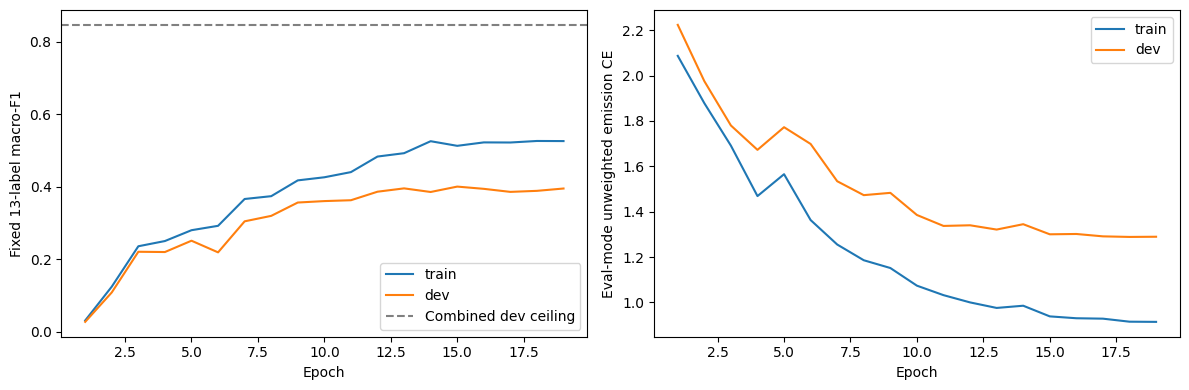

DIAGNOSTICS: /kaggle/working/cs781_phase3/runs/decoder_rr_ia3_001_diagnostics.zip
RESUMABLE BACKUP: /kaggle/working/cs781_phase3/runs/decoder_rr_ia3_001_backup.zip
SUBMISSION: /kaggle/working/cs781_phase3/runs/decoder_rr_ia3_001_submission.zip
BEST TRAINABLE CHECKPOINT: /kaggle/working/cs781_phase3/runs/decoder_rr_ia3_001/best_rr.pt
Original Phase 1 dependency SHA256: fd5add7ccc1d519a6f547fbd9a5c86a53276db8e09fb93c165d96531685d0bb7


In [18]:
import matplotlib.pyplot as plt

history = read_json(RUN_DIR / 'history.json')
epochs = [row for row in history if row['kind'] == 'epoch']
if epochs:
    x = [row['epoch'] for row in epochs]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for split, color in [('train', 'tab:blue'), ('dev', 'tab:orange')]:
        axes[0].plot(x, [r[split]['combined']['macro_f1'] for r in epochs], label=split, color=color)
        axes[1].plot(x, [r[split]['losses']['unweighted_sentence_ce'] for r in epochs], label=split, color=color)
    axes[0].axhline(11/13, linestyle='--', color='gray', label='Combined dev ceiling')
    axes[0].set(xlabel='Epoch', ylabel='Fixed 13-label macro-F1')
    axes[1].set(xlabel='Epoch', ylabel='Eval-mode unweighted emission CE')
    for axis in axes:
        axis.legend()
    fig.tight_layout()
    fig.savefig(RUN_DIR / 'training_curves.png', dpi=150)
    plt.show()

diagnostics_zip, backup_zip = save_diagnostics(RUN_DIR)
print('DIAGNOSTICS:', diagnostics_zip)
print('RESUMABLE BACKUP:', backup_zip)
print('SUBMISSION:', run_summary['submission_zip'])
print('BEST TRAINABLE CHECKPOINT:', RUN_DIR / 'best_rr.pt')
print('Original Phase 1 dependency SHA256:', protocol['phase1_checkpoint_sha256'])

## 9. Lower-rate continuation

The continuation loads the initial run's best IA³ and task weights and starts a fresh AdamW optimizer, cosine schedule and gradient scaler. I reduced the IA³, head and CRF peak rates to `3e-4`, `1e-4` and `3e-4` respectively. The stage ran for 14 additional epochs, selected stage epoch 8 and exported `decoder_rr_ia3_001_continue_001_submission.zip`.


In [20]:
import copy
import random
import shutil
from pathlib import Path

import numpy as np
import torch
from rr_data import file_hash, read_json, write_json
from rr_model import load_trainable_state, trainable_state
from rr_engine import train, export_selected, save_diagnostics, atomic_checkpoint

required = ('ROOT', 'SRC', 'SETTINGS', 'model', 'documents', 'train_windows',
            'dev_windows', 'test_windows', 'labels', 'weights', 'phase1_checkpoint',
            'tokenizer_sha', 'EXPECTED_RR_HASHES')
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError('Use these cells in the original initialized notebook. Missing: ' + ', '.join(missing))

PARENT_DIR = ROOT / 'runs' / 'decoder_rr_ia3_001'
CONT_RUN_ID = 'decoder_rr_ia3_001_continue_001'
CONT_DIR = ROOT / 'runs' / CONT_RUN_ID
parent_path = PARENT_DIR / 'best_rr.pt'
if not parent_path.exists():
    raise FileNotFoundError('Restore the original RR backup first: ' + str(parent_path))

parent = torch.load(parent_path, map_location='cpu', weights_only=False)
parent_protocol = parent['protocol']
if parent_protocol != read_json(PARENT_DIR / 'protocol.json'):
    raise ValueError('Parent checkpoint and protocol differ.')
if parent_protocol['labels'] != labels or parent_protocol['class_weights'] != weights.tolist():
    raise ValueError('Current labels or class weights differ from the parent run.')
if file_hash(phase1_checkpoint) != parent_protocol['phase1_checkpoint_sha256']:
    raise ValueError('Current Phase 1 backbone differs from the parent run.')
if tokenizer_sha != parent_protocol['tokenizer_sha256'] or EXPECTED_RR_HASHES != parent_protocol['rr_data_hashes']:
    raise ValueError('Current tokenizer or data differ from the parent run.')
for name, expected in parent_protocol['source_sha256'].items():
    if file_hash(SRC / name) != expected:
        raise ValueError('Source differs from the trained run: ' + name)
for key, expected in parent_protocol['settings'].items():
    if SETTINGS.get(key) != expected:
        raise ValueError('Keep the original notebook settings before running this add-on: ' + key)

CONT_SETTINGS = copy.deepcopy(SETTINGS)
CONT_SETTINGS.update(epochs=15, minimum_epochs=6, patience=6,
                     ia3_lr=3e-4, head_lr=1e-4, crf_lr=3e-4)
CONT_PROTOCOL = copy.deepcopy(parent_protocol)
CONT_PROTOCOL['run_id'] = CONT_RUN_ID
CONT_PROTOCOL['settings'].update({key: CONT_SETTINGS[key] for key in parent_protocol['settings']})
CONT_PROTOCOL['initialization'] = {
    'kind': 'supervised_rr_checkpoint_continuation',
    'parent_run_id': parent_protocol['run_id'],
    'parent_selected_epoch': parent['epoch'],
    'parent_checkpoint_sha256': file_hash(parent_path),
    'parent_dev_macro_f1': parent['metrics']['combined']['macro_f1'],
    'optimizer': 'Fresh AdamW, cosine scheduler and GradScaler for this continuation stage.',
    'epoch_numbering': 'Stage epochs; epoch zero is the selected parent checkpoint.',
}
CONT_DIR.mkdir(parents=True, exist_ok=True)
protocol_path = CONT_DIR / 'protocol.json'
if protocol_path.exists() and read_json(protocol_path) != CONT_PROTOCOL:
    raise ValueError('Continuation directory has another protocol; choose another CONT_RUN_ID.')
if (CONT_DIR / 'last.pt').exists() and not protocol_path.exists():
    raise ValueError('Continuation checkpoint is missing its protocol record.')
write_json(protocol_path, CONT_PROTOCOL)
write_json(CONT_DIR / 'initialization.json', CONT_PROTOCOL['initialization'])
(CONT_DIR / 'sources').mkdir(exist_ok=True)
for name in parent_protocol['source_sha256']:
    shutil.copy2(SRC / name, CONT_DIR / 'sources' / name)
for name in ('environment.json', 'data_record.json', 'method_sources.json'):
    if (PARENT_DIR / name).exists():
        shutil.copy2(PARENT_DIR / name, CONT_DIR / name)
inherited_smoke = read_json(PARENT_DIR / 'smoke_checks.json')
if inherited_smoke.get('status') != 'passed':
    raise RuntimeError('The parent smoke checks must have passed.')
inherited_smoke['continuation_note'] = 'Inherited from the parent; architecture, batching and loss code are identical.'
write_json(CONT_DIR / 'smoke_checks.json', inherited_smoke)

initial_path = CONT_DIR / 'initial_rr_state.pt'
if initial_path.exists():
    initial = torch.load(initial_path, map_location='cpu', weights_only=False)
    if initial['protocol'] != CONT_PROTOCOL:
        raise ValueError('Continuation initial-state protocol differs.')
    load_trainable_state(model, initial['trainable_state'])
    del initial
else:
    load_trainable_state(model, parent['trainable_state'])
    atomic_checkpoint(initial_path, {'protocol': CONT_PROTOCOL, 'trainable_state': trainable_state(model)})
del parent
model.zero_grad(set_to_none=True)
if not (CONT_DIR / 'last.pt').exists():
    random.seed(CONT_SETTINGS['seed'])
    np.random.seed(CONT_SETTINGS['seed'])
    torch.manual_seed(CONT_SETTINGS['seed'])
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(CONT_SETTINGS['seed'])
print('Continuation:', CONT_DIR)
print('Parent selected epoch:', CONT_PROTOCOL['initialization']['parent_selected_epoch'])
print('Parent dev macro-F1:', CONT_PROTOCOL['initialization']['parent_dev_macro_f1'])
print('Up to 15 additional epochs; patience 6. Parent checkpoint is eligible at stage epoch zero.')

Continuation: /kaggle/working/cs781_phase3/runs/decoder_rr_ia3_001_continue_001
Parent selected epoch: 15
Parent dev macro-F1: 0.3998934608944722
Up to 15 additional epochs; patience 6. Parent checkpoint is eligible at stage epoch zero.


In [21]:
cont_state = train(model, documents, train_windows, dev_windows, labels, weights,
    CONT_SETTINGS, CONT_PROTOCOL, CONT_DIR, SRC / 'evaluate_phase3.py')
write_json(CONT_DIR / 'training_state_summary.json',
           {key: value for key, value in cont_state.items() if key != 'history'})
print('Completed:', cont_state['completed'], '| best stage epoch:', cont_state['best_epoch'],
      '| best dev macro-F1:', cont_state['best_f1'])

Epoch 1: batches 2/99 | CRF/sentence 0.7065 | weighted CE 1.0259 | updates 1 | skipped 0
Epoch 1: batches 20/99 | CRF/sentence 0.5797 | weighted CE 0.9675 | updates 10 | skipped 0
Epoch 1: batches 40/99 | CRF/sentence 0.4533 | weighted CE 0.7093 | updates 20 | skipped 0
Epoch 1: batches 60/99 | CRF/sentence 0.5141 | weighted CE 0.8332 | updates 30 | skipped 0
Epoch 1: batches 80/99 | CRF/sentence 0.7881 | weighted CE 1.0685 | updates 40 | skipped 0
Epoch 1: batches 99/99 | CRF/sentence 1.2083 | weighted CE 1.6272 | updates 50 | skipped 0
Epoch 1: train F1 0.5013 | dev F1 0.3815 / ceiling 0.8462 | CL 0.3438 | IT 0.3387 | best epoch 0
Epoch 2: batches 2/99 | CRF/sentence 0.8795 | weighted CE 1.3224 | updates 51 | skipped 0
Epoch 2: batches 20/99 | CRF/sentence 1.5873 | weighted CE 2.3000 | updates 60 | skipped 0
Epoch 2: batches 40/99 | CRF/sentence 0.8769 | weighted CE 1.1785 | updates 70 | skipped 0
Epoch 2: batches 60/99 | CRF/sentence 0.8343 | weighted CE 1.3399 | updates 80 | skippe

CL documents: 5
IT documents: 5
Total documents: 10
Total sentences: 2142
Macro-F1:        0.424955
Macro-Precision: 0.500506
Macro-Recall:    0.416395

Selected epoch: 8 | submission: /kaggle/working/cs781_phase3/runs/decoder_rr_ia3_001_continue_001_submission.zip


,precision,recall,f1,support,predicted
Fact,0.763636,0.662162,0.709288,444.0,385.0
Issue,1.000000,0.200000,0.333333,15.0,3.0
ArgumentPetitioner,0.485075,0.325000,0.389222,400.0,268.0
ArgumentRespondent,0.439320,0.665441,0.529240,272.0,412.0
Statute,0.779661,0.766667,0.773109,120.0,118.0
Dissent,0.000000,0.000000,0.000000,0.0,0.0
PrecedentReliedUpon,0.588235,0.551181,0.569106,254.0,238.0
PrecedentNotReliedUpon,0.518519,0.560000,0.538462,50.0,54.0
PrecedentOverruled,0.000000,0.000000,0.000000,0.0,0.0
RulingByLowerCourt,0.535714,0.147059,0.230769,102.0,28.0


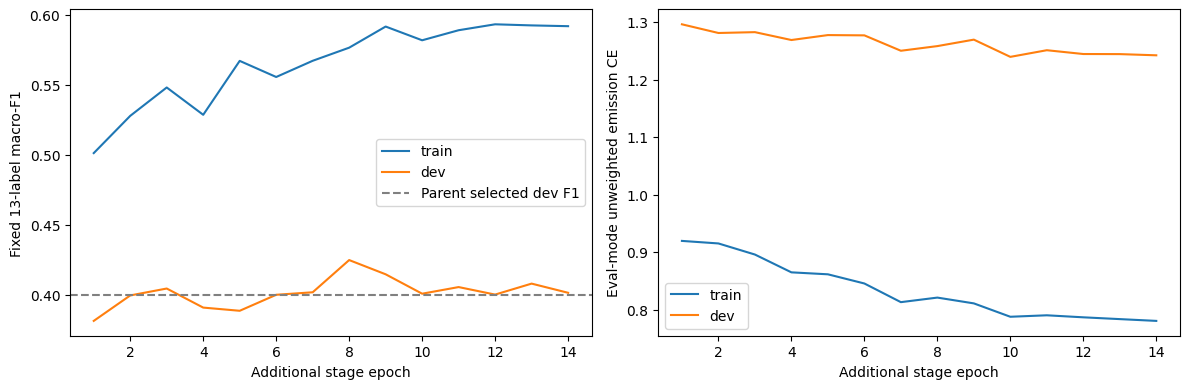

Parent dev F1: 0.399893 | selected continuation F1: 0.424955 | change: +0.025062
DIAGNOSTICS: /kaggle/working/cs781_phase3/runs/decoder_rr_ia3_001_continue_001_diagnostics.zip
BACKUP: /kaggle/working/cs781_phase3/runs/decoder_rr_ia3_001_continue_001_backup.zip
SUBMISSION: /kaggle/working/cs781_phase3/runs/decoder_rr_ia3_001_continue_001_submission.zip


In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cont_summary = export_selected(model, documents, dev_windows, test_windows, labels,
    CONT_SETTINGS, CONT_PROTOCOL, CONT_DIR, SRC / 'evaluate_phase3.py')
cont_summary['training_completed'] = cont_state['completed']
cont_summary['initialization'] = CONT_PROTOCOL['initialization']
write_json(CONT_DIR / 'run_summary.json', cont_summary)
per_label = pd.DataFrame(cont_summary['selected_dev']['combined']['per_label']).T
display(per_label)
per_label.to_csv(CONT_DIR / 'selected_dev_per_label.csv', index_label='label')

cont_history = read_json(CONT_DIR / 'history.json')
cont_epochs = [row for row in cont_history if row['kind'] == 'epoch']
if cont_epochs:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    x = [row['epoch'] for row in cont_epochs]
    for split, color in [('train', 'tab:blue'), ('dev', 'tab:orange')]:
        axes[0].plot(x, [r[split]['combined']['macro_f1'] for r in cont_epochs], label=split, color=color)
        axes[1].plot(x, [r[split]['losses']['unweighted_sentence_ce'] for r in cont_epochs], label=split, color=color)
    axes[0].axhline(CONT_PROTOCOL['initialization']['parent_dev_macro_f1'],
                    linestyle='--', color='gray', label='Parent selected dev F1')
    axes[0].set(xlabel='Additional stage epoch', ylabel='Fixed 13-label macro-F1')
    axes[1].set(xlabel='Additional stage epoch', ylabel='Eval-mode unweighted emission CE')
    for axis in axes:
        axis.legend()
    fig.tight_layout()
    fig.savefig(CONT_DIR / 'training_curves.png', dpi=150)
    plt.show()

cont_diagnostics, cont_backup = save_diagnostics(CONT_DIR)
old_f1 = CONT_PROTOCOL['initialization']['parent_dev_macro_f1']
new_f1 = cont_summary['selected_dev']['combined']['macro_f1']
print(f'Parent dev F1: {old_f1:.6f} | selected continuation F1: {new_f1:.6f} | change: {new_f1-old_f1:+.6f}')
print('DIAGNOSTICS:', cont_diagnostics)
print('BACKUP:', cont_backup)
print('SUBMISSION:', cont_summary['submission_zip'])

## References

- Activation scaling. [IA³](https://arxiv.org/abs/2205.05638)
- Context-aware legal sentence classification. [Semantic Segmentation of Legal Documents via Rhetorical Roles](https://aclanthology.org/2022.nllp-1.13/)
- Learned sequence scores and Viterbi decoding. [Neural Architectures for Named Entity Recognition](https://aclanthology.org/N16-1030/)
